# **Second-hand House Price Analysis**

เนื่องจากครอบครัวทำธุรกิจขายบ้านมือสองในจังหวัดสระบุรี และได้สังเกตเห็นว่า Key สำคัญในการตัดสินใจซื้อบ้านของลูกค้าหลังจากมีการพูดคุยกันอย่างจริงจังมาระยะหนึ่งคือ "ปัจจัยเรื่องราคา" ราคาเป็นปัจจัยที่สำคัญที่สุด แม้ว่าจะได้บ้านในทำเลที่ลูกค้าต้องการแล้ว แต่หากราคายังไม่เหมาะสม ลูกค้าพร้อมจะทิ้งบ้านหลังนั้นและหาบ้านหลังใหม่ทันที

นอกจากนี้จากการพูดคุยกับเจ้าของธุรกิจ ยังได้ข้อมูลที่สำคัญอีกอย่างคือ การที่ราคาถูกต้องเหมาะสมตั้งแต่แรก จะช่วยให้บ้านเป็นที่สนใจ และขายออกได้ค่อนข้างไว รวมถึงการพูดคุยเรื่องการซื้อขายเป็นไปได้อย่างราบรื่นมากกว่า เมื่อเทียบกับบ้านที่ตั้งราคาไม่เหมาะสม

>ดังนั้นโปรเจคนี้จึงพยายามจะกลั่นกรองประสบการณ์ของเจ้าของธุรกิจ ให้ออกมาเป็น ***โมเดลที่สามารถทำนายราคาบ้านอย่างเหมาะสมได้***
โดยใช้ข้อมูลที่มีอย่างจำกัดให้เป็นประโยชน์สูงสุด


**สถานะ :**
งานนี้เป็น proof of concept ที่ใช้ข้อมูลบ้านมือสองที่ขายแล้ว 37 หลังจากธุรกิจของครอบครัวเพียงแห่งเดียว ***ดังนั้นทุกอย่างที่ทำในโปรเจคนี้อยู่บนพื้นฐานของข้อมูลที่จำกัด*** จึงเน้นแสดงแนวทางการวิเคราะห์และเหตุผลของการตัดสินใจเชิงวิธีการ ตัวเลขที่ได้ยังไม่ควรนำไปใช้จริง

**ผลลัพธ์โดยสรุป**

* **โจทย์:** ทำนายราคาขายบ้านมือสองในสระบุรี (บ้านเดี่ยวและทาวน์เฮ้าส์) จากข้อมูลบ้านที่ขายแล้ว 37 หลังของธุรกิจครอบครัว

* **วิธี:** linear regression บน log ของราคา โดยใช้จำนวนห้องนอน คะแนนสภาพบ้าน ประเภทบ้าน และพื้นที่เป็นตัวแปร ประเมินด้วย LOOCV (ทดสอบทีละหลัง โดยโมเดลไม่เคยเห็นบ้านหลังนั้นตอนเทรน)

* **ความแม่นยำ:** ประเมินกับบ้าน 36 หลัง (โมเดลไม่รวมบ้านแฝด) median error อยู่ที่ประมาณ 170,000 บาท (13.4%) เทียบกับ baseline ที่ดีที่สุด (ทายด้วยราคาเฉลี่ยแยกตามประเภทบ้าน) ที่ 308,000 บาท (21.3%) โดยบ้านจำนวน 72% ถูกทำนายคลาดเคลื่อนไม่เกิน 20% แต่มี 4 หลัง (11%) ที่คลาดเคลื่อนเกิน 30%

* **สิ่งที่พบ:** สภาพบ้าน จำนวนห้องนอน และประเภทบ้านสัมพันธ์กับราคาอย่างมีนัยสำคัญ ส่วนการรีโนเวทไม่พบหลักฐานว่าทำให้ราคาสูงขึ้น เมื่อควบคุมสภาพบ้านแล้ว (p = 0.636) สิ่งที่สัมพันธ์กับราคาคือสภาพบ้านที่ดีกว่า อย่างไรก็ตาม บ้านที่รีโนเวทและไม่รีโนเวทซึ่งมีคะแนนสภาพบ้านเท่ากันเปรียบเทียบกันได้เพียง 2 ระดับคะแนน จึงยังสรุปแน่ชัดไม่ได้

* **ขอบเขตและข้อจำกัด:** ข้อมูลมีน้อย (37 หลัง) และมาจากธุรกิจเดียว จึงเป็น proof of concept และตัวเลขยังไม่ควรนำไปใช้จริง **โมเดลนี้ยังไม่ครอบคลุมบ้านแฝดด้วย**




# 1.Libraries Used

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.float_format', '{:,.3f}'.format)

In [3]:
sns.set_theme( style = "whitegrid", palette = "pastel", rc = {"figure.figsize": (15, 5)} )

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
import statsmodels.formula.api as smf

# 2.Load data

In [5]:
df = pd.read_csv("Houseinfo_end2024to072026.csv")

In [ ]:
df.drop(columns = ["ID โพสต์","ชื่อบ้าน","ชื่อบ้าน.1", "Unnamed: 8", "ลิงก์ facebook", "เวลาที่เผยแพร่ (แปซิฟิก)", "รายละเอียดทั้งหมด", "เวลาที่เผยแพร่ (ไทย).1", "ลิงก์ facebook.1", "ID โพสต์.1", "รายละเอียดทั้งหมด.1", "zone"]).head()

In [7]:
df.shape

(2432, 34)

In [ ]:
df.info()

In [ ]:
df.isnull().sum()

# 3.Data Cleaning and Feature engineering

#### Remove the irrelevant original tables

In [10]:
df1 = df.iloc[:, 11: ].copy().reset_index(drop = True)

In [11]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2432 entries, 0 to 2431
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   House_ID                102 non-null    object 
 1   ID โพสต์.1              102 non-null    object 
 2   เวลาที่เผยแพร่ (ไทย).1  102 non-null    object 
 3   ลิงก์ facebook.1        102 non-null    object 
 4   รายละเอียดทั้งหมด.1     102 non-null    object 
 5   ชื่อบ้าน.1              102 non-null    object 
 6   สถานะ                   102 non-null    object 
 7   ราคา.1                  102 non-null    object 
 8   ค่าโอน                  102 non-null    object 
 9   ห้องนอน                 102 non-null    float64
 10  ห้องน้ำ                 102 non-null    float64
 11  ที่จอดรถ                102 non-null    float64
 12  กี่ชั้น                 102 non-null    float64
 13  ประเภทบ้าน              102 non-null    object 
 14  อำเภอ                   102 non-null    

#### df1

In [ ]:
df1.drop(columns = ["ID โพสต์.1", "ชื่อบ้าน.1", "ลิงก์ facebook.1", "รายละเอียดทั้งหมด.1", "zone"])

In [ ]:
df1.isnull().sum()

In [14]:
df1 = df1.dropna(how = "all")

In [ ]:
df1.drop(columns = ["ID โพสต์.1", "ชื่อบ้าน.1", "ลิงก์ facebook.1", "รายละเอียดทั้งหมด.1", "zone"])

บ้านที่กำลังลงขายอยู่ (สถานะ active) และบ้านที่เคยลงขายแต่ถอนออกไปแล้ว (สถานะ withdrawn) ยังไม่มีค่า score เนื่องจากยังไม่ได้กรอกข้อมูลคะแนน ไม่ใช่เพราะประเมินบ้านเหล่านั้นไม่ได้ จึงกรอกคะแนนเฉพาะบ้านที่ขายแล้ว (sold) ก่อน เพราะเป็นกลุ่มที่ใช้วิเคราะห์ในโปรเจกต์นี้ บ้านมือสองที่ขายแล้ว 37 หลังซึ่งใช้วิเคราะห์มี score ครบทุกหลัง ค่าว่างที่เหลือจึงไม่ส่งผลต่อการวิเคราะห์

In [ ]:
df1 = df1.drop(['ID โพสต์.1', 'ลิงก์ facebook.1', 'รายละเอียดทั้งหมด.1', 'zone', 'by_MBS'], axis = 'columns')

df1.head().drop(columns = ['ชื่อบ้าน.1'])

In [17]:
df1.columns = ["house_id", "date", "name", "status",
               "soldprice", "transfer_fee", "bedroom",
               "bathroom", "parking", "floor", "house_type",
               "district", "sub_district", "score", "is_renovated",
               "is_newbuild", "close_date", "days_on_market"]

In [18]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 102 entries, 0 to 101
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   house_id        102 non-null    object 
 1   date            102 non-null    object 
 2   name            102 non-null    object 
 3   status          102 non-null    object 
 4   soldprice       102 non-null    object 
 5   transfer_fee    102 non-null    object 
 6   bedroom         102 non-null    float64
 7   bathroom        102 non-null    float64
 8   parking         102 non-null    float64
 9   floor           102 non-null    float64
 10  house_type      102 non-null    object 
 11  district        102 non-null    object 
 12  sub_district    102 non-null    object 
 13  score           41 non-null     float64
 14  is_renovated    102 non-null    float64
 15  is_newbuild     102 non-null    float64
 16  close_date      102 non-null    object 
 17  days_on_market  102 non-null    object 


In [19]:
df1.describe()

,bedroom,bathroom,parking,floor,score,is_renovated,is_newbuild
count,102.000,102.000,102.000,102.000,41.000,102.000,102.000
mean,2.578,1.833,1.618,1.314,3.902,0.529,0.108
std,0.636,0.785,0.704,0.466,1.210,0.502,0.312
min,2.000,1.000,1.000,1.000,1.000,0.000,0.000
25%,2.000,1.000,1.000,1.000,3.500,0.000,0.000
50%,3.000,2.000,2.000,1.000,4.000,1.000,0.000
75%,3.000,2.000,2.000,2.000,5.000,1.000,0.000
max,5.000,5.000,4.000,2.000,5.000,1.000,1.000


In [ ]:
df1.drop(columns = ['name'])

In [21]:
df1 = df1.replace("-", np.nan)

In [22]:
df1 = df1.map(lambda x: x.strip() if isinstance(x, str) else x)

df1.columns = df1.columns.str.strip()

In [ ]:
df1.drop(columns = ['name']).head()

##### transfer_fee column

In [24]:
df1.transfer_fee.value_counts()

,count
transfer_fee,
ฟรีโอน,66
ไม่แจ้ง,20
ค่าโอน 50/50,13
ค่าโอน50/50,2
ค่าโอน50,1


In [25]:
df1.loc[(df1['transfer_fee'] == 'ค่าโอน 50/50')|(df1['transfer_fee'] == 'ค่าโอน50/50')|(df1['transfer_fee'] == 'ค่าโอน50'), 'transfer_fee'] = 'half'

In [26]:
df1.loc[(df1['transfer_fee'] == 'ฟรีโอน'), 'transfer_fee'] = 'free'

In [27]:
df1.loc[(df1['transfer_fee'] == 'ไม่แจ้ง'), 'transfer_fee'] = 'unspecified'

In [28]:
df1.transfer_fee.value_counts()

,count
transfer_fee,
free,66
unspecified,20
half,16


##### house_type column

In [29]:
df1.house_type.value_counts()

,count
house_type,
ทาวน์เฮ้าส์,55
บ้านเดี่ยว,43
บ้านแฝด,4


In [30]:
df1['house_type'] = df1['house_type'].replace({'ทาวน์เฮ้าส์':'townhouse',
                                               'บ้านเดี่ยว':'singlehouse',
                                               'บ้านแฝด':'twinhouse'}
                                             )

In [31]:
df1['house_type']

,house_type
0,townhouse
1,twinhouse
2,twinhouse
3,townhouse
4,townhouse
...,...
97,townhouse
98,singlehouse
99,singlehouse
100,townhouse


##### score column

> score หรือคะแนนสภาพบ้าน (1-5) ให้โดยผู้ประเมินของบริษัทตามเกณฑ์ของบริษัท ในขั้นตอนตรวจบ้านก่อนรับฝากขาย จึงเป็นคะแนนที่ให้ก่อนจะทราบราคาขาย เกณฑ์ที่ใช้พิจารณา เช่น โครงสร้างภายนอกของบ้าน สภาพภายในบ้าน (การซ่อมแซม) และความสวยงามโดยรวม เป็นต้น

In [32]:
df1.score.value_counts().sort_index()

,count
score,
1.000,2
2.000,5
2.500,1
3.000,1
3.500,5
4.000,9
4.500,2
5.000,16


##### soldprice column

In [33]:
df1.soldprice.dtypes

dtype('O')

In [34]:
df1['soldprice'].head()

,soldprice
0,"950,000"
1,"2,390,000"
2,"1,890,000"
3,"1,500,000"
4,"1,750,000"


In [35]:
df1['soldprice'] = df1['soldprice'].str.replace(',', '', regex = False)

In [36]:
df1['soldprice'] = df1['soldprice'].astype('int')

In [37]:
df1['soldprice'].head()

,soldprice
0,950000
1,2390000
2,1890000
3,1500000
4,1750000


In [38]:
df1.dtypes

,0
house_id,object
date,object
name,object
status,object
soldprice,int64
transfer_fee,object
bedroom,float64
bathroom,float64
parking,float64
floor,float64


##### days_on_market column

In [39]:
df1['days_on_market'] = df1['days_on_market'].astype('Int64')

In [40]:
df1['days_on_market'].dtype

Int64Dtype()

##### is_renovated column

In [41]:
df1 = df1.astype({"is_renovated":bool})

In [42]:
df1['is_renovated']

,is_renovated
0,True
1,False
2,False
3,True
4,True
...,...
97,False
98,True
99,True
100,False


##### district and subdistrict columns

In [43]:
df1.district.unique().tolist()

['แก่งคอย', 'เมือง', 'หนองแค', 'เฉลิมพระเกียรติ', 'เสาไห้', 'วังม่วง']

In [44]:
df1.sub_district.unique().tolist()

[nan,
 'ปากเพรียว',
 'โคกสว่าง',
 'ตะกุด',
 'ดาวเรือง',
 'นาโฉง',
 'ตลิ่งชัน',
 'หนองยาว',
 'กุดนกเปล้า',
 'หนองปลาไหล',
 'ปากข้าวสาร',
 'ผึ้งรวง',
 'หนองโน']

In [45]:
district_map = {"แก่งคอย": "kaengkhoi",
                "เมือง": "muang",
                "หนองแค": "nongkae",
                "เฉลิมพระเกียรติ": "chaloemphrakiat",
                "เสาไห้": "saohai",
                "วังม่วง": "wangmuang",
                }

In [46]:
subdistrict_map = {"กุดนกเปล้า": "kudnokplao",
                   "ดาวเรือง": "daoruang",
                   "ตลิ่งชัน": "talingchun",
                   "ตะกุด": "takut",
                   "หนองปลาไหล": "nongplalai",
                   "หนองยาว":"nongyao",
                   "หนองโน":"nongno",
                   "โคกสว่าง":"khoksawang",
                   "ปากเพรียว":"pakphriao",
                   "ปากข้าวสาร":"pakkhaosan",
                   "นาโฉง":"nachong",
                   "ผึ้งรวง":"phuengruang",
                  }

In [47]:
df1["district"] = df1["district"].replace(district_map)

In [48]:
df1["sub_district"] = df1["sub_district"].replace(subdistrict_map)

In [49]:
df1[["district", "sub_district"]]

,district,sub_district
0,kaengkhoi,NaN
1,kaengkhoi,NaN
2,muang,pakphriao
3,muang,pakphriao
4,muang,pakphriao
...,...,...
97,saohai,NaN
98,kaengkhoi,NaN
99,muang,pakphriao
100,saohai,NaN


#### filter only sold status and remove new build and days on market

In [50]:
df_sold = df1[ df1['status'] == 'sold' ].copy().reset_index(drop = True)

In [51]:
df_sold = df_sold[ df_sold['is_newbuild'] == 0 ]

In [52]:
df_sold = df_sold.drop(columns = ['is_newbuild'])

In [53]:
df_sold = df_sold.drop(columns = ['days_on_market'])

In [54]:
df_sold = df_sold.reset_index(drop = True)

In [55]:
df_sold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   house_id      37 non-null     object 
 1   date          37 non-null     object 
 2   name          37 non-null     object 
 3   status        37 non-null     object 
 4   soldprice     37 non-null     int64  
 5   transfer_fee  37 non-null     object 
 6   bedroom       37 non-null     float64
 7   bathroom      37 non-null     float64
 8   parking       37 non-null     float64
 9   floor         37 non-null     float64
 10  house_type    37 non-null     object 
 11  district      37 non-null     object 
 12  sub_district  18 non-null     object 
 13  score         37 non-null     float64
 14  is_renovated  37 non-null     bool   
 15  close_date    37 non-null     object 
dtypes: bool(1), float64(5), int64(1), object(9)
memory usage: 4.5+ KB


In [56]:
df_sold.shape

(37, 16)

#### Add area column

In [57]:
df_sold['district'].value_counts()

,count
district,
muang,18
saohai,9
kaengkhoi,6
nongkae,3
chaloemphrakiat,1


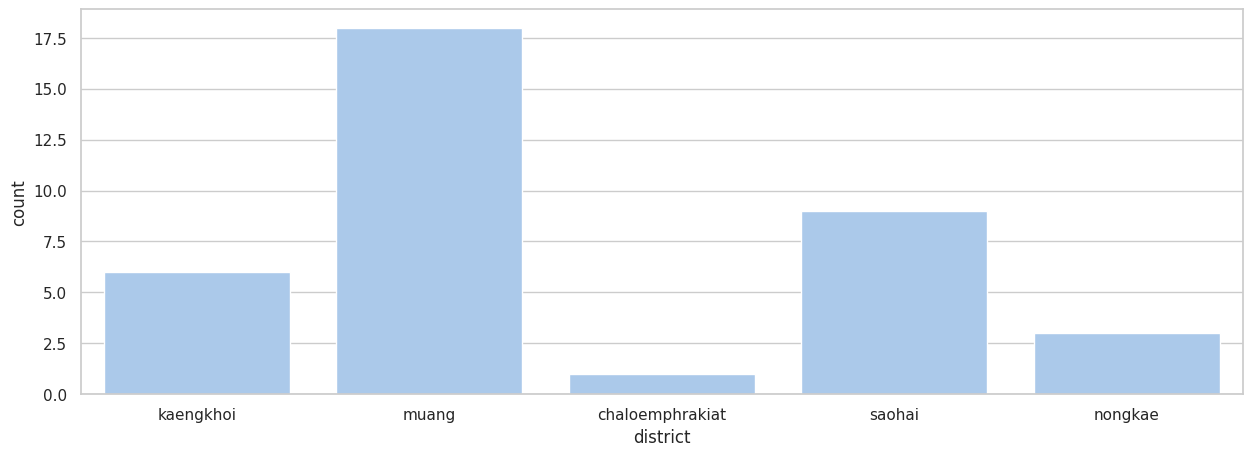

In [58]:
sns.countplot(x = df_sold["district"])
plt.show()

In [59]:
df_sold['sub_district'].value_counts()

,count
sub_district,
pakphriao,9
phuengruang,3
daoruang,2
nachong,1
talingchun,1
pakkhaosan,1
takut,1


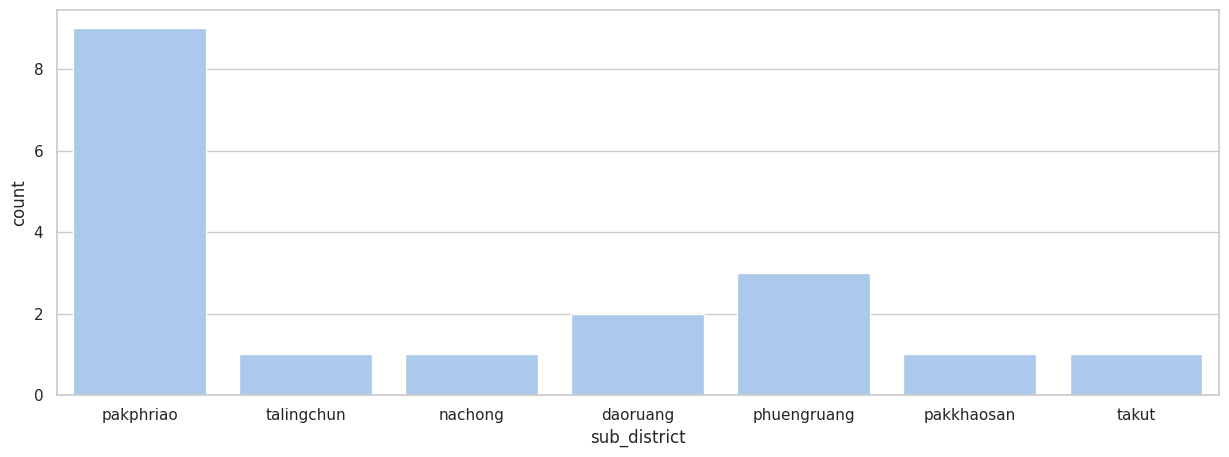

In [60]:
sns.countplot(x = df_sold["sub_district"])
plt.show()

In [61]:
df_sold["area"] = df_sold["sub_district"].fillna(df_sold["district"])

In [ ]:
df_sold.drop(columns = ['name']).head()

In [63]:
df_sold.loc[(df_sold['district'] == 'muang')&(df_sold['sub_district'] == 'pakphriao'), 'area'] = 'muang_pakphriao'

In [64]:
df_sold.loc[(df_sold['district'] == 'muang')&(df_sold['sub_district'] != 'pakphriao'), 'area'] = 'muang_others'

In [65]:
df_sold.loc[(df_sold['district'] == 'nongkae')|(df_sold['district'] == 'chaloemphrakiat') , 'area'] = 'others_district'

In [66]:
df_sold.area.value_counts()

,count
area,
muang_pakphriao,9
saohai,9
muang_others,9
kaengkhoi,6
others_district,4


# 4.EDA

In [ ]:
df_sold.drop(columns = ['name']).head()

#### df_sold['soldprice']

In [68]:
df_sold['soldprice'].describe().apply('{:,.0f}'.format)

,soldprice
count,37
mean,"1,472,703"
std,"628,290"
min,"600,000"
25%,"950,000"
50%,"1,350,000"
75%,"1,900,000"
max,"2,850,000"


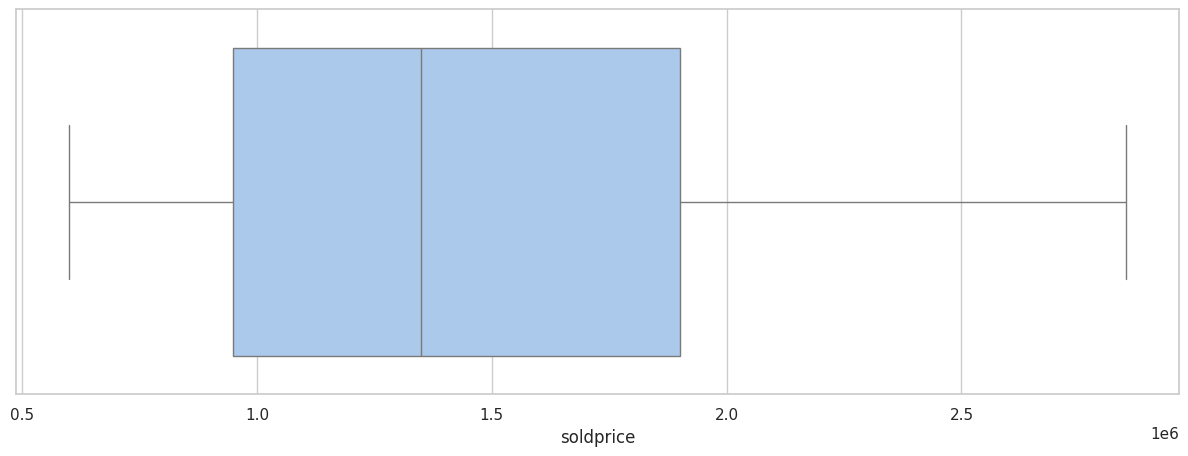

In [69]:
sns.boxplot(x = df_sold['soldprice'])
plt.show()

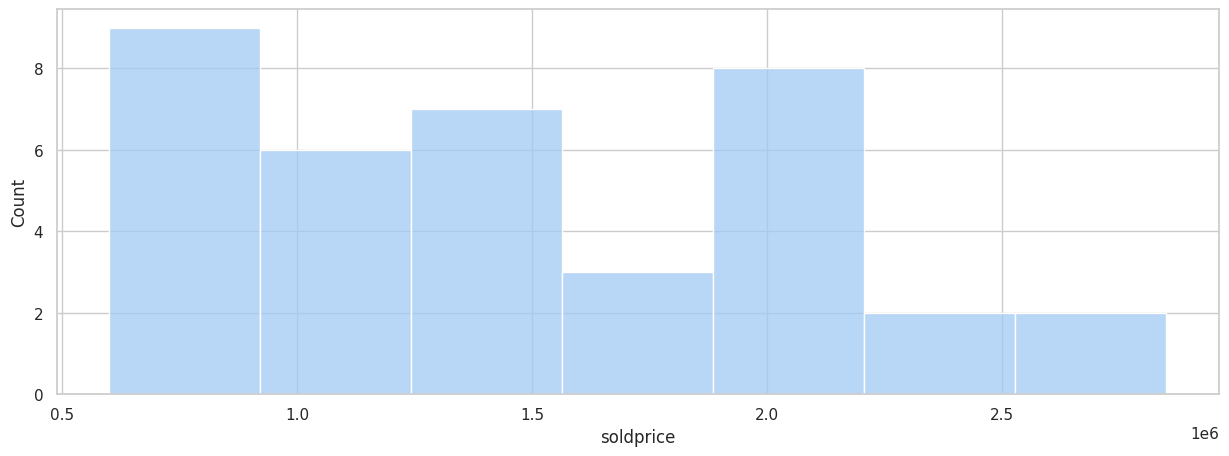

In [70]:
sns.histplot(x = df_sold['soldprice'])
plt.show()

#### df_sold['house_type']

In [71]:
df_sold.house_type.value_counts()

,count
house_type,
townhouse,23
singlehouse,13
twinhouse,1


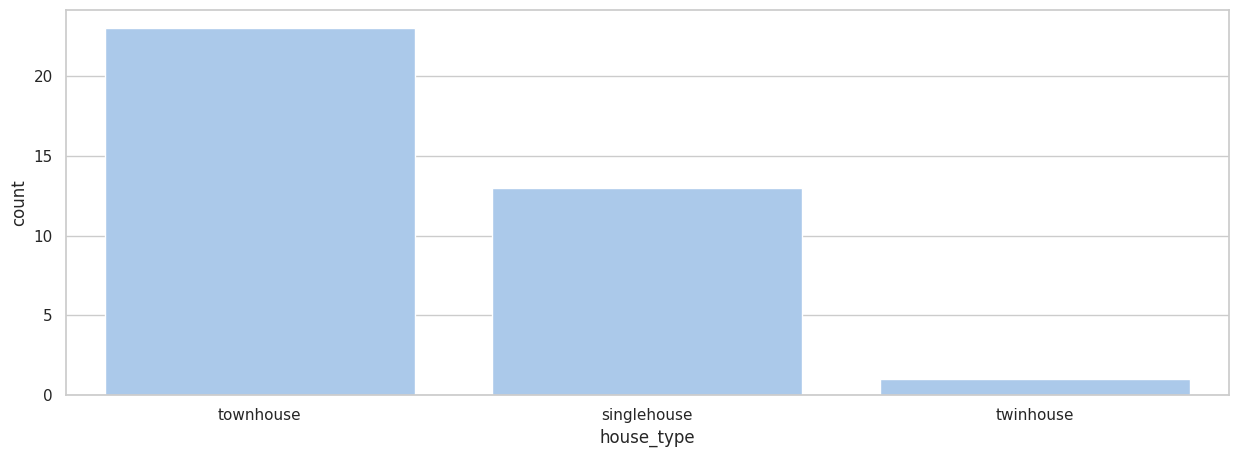

In [72]:
sns.countplot(data = df_sold, x = "house_type")
plt.show()

In [ ]:
df_sold.query(' house_type == "twinhouse" ').drop(columns = ['name'])

จากบ้านทั้งหมด 37 หลัง มีเพียง 1 หลังที่เป็นบ้านแฝด (twinhouse) ซึ่งเป็นข้อมูลในแถวที่ 20 (index)

> ดังนั้น เมื่อทำ one-hot encoding ตัวแปร dummy ของ twinhouse จะมีข้อมูลเพียง 1 แถวเช่นกัน

#### df_sold['is_renovated']

In [74]:
df_sold.is_renovated.value_counts()

,count
is_renovated,
True,26
False,11


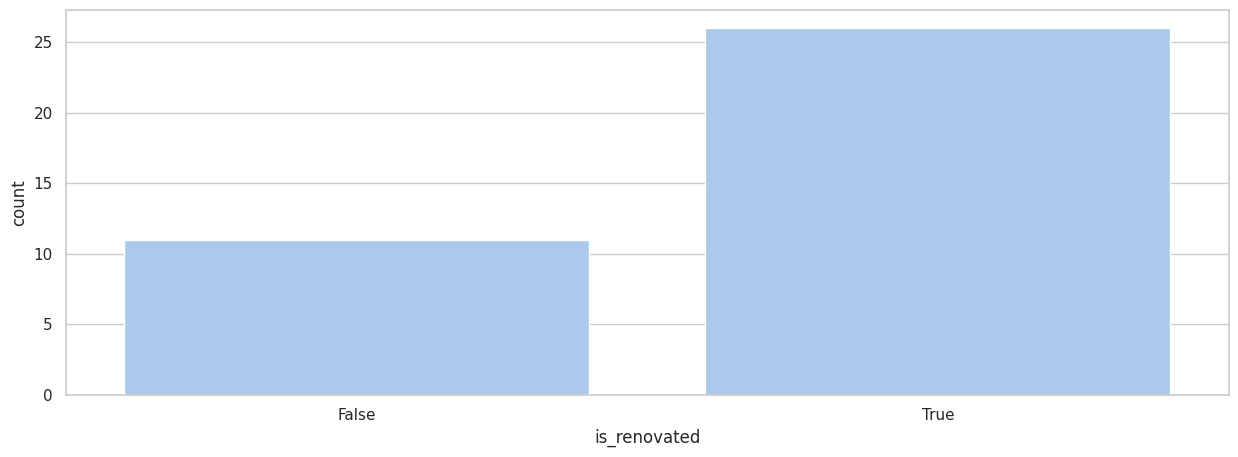

In [75]:
sns.countplot(data = df_sold, x = "is_renovated")
plt.show()

จากข้อมูลทั้งหมด บ้านส่วนใหญ่เป็นบ้านที่ผ่านการรีโนเวทแล้ว

##### Outlier by group is_renovated

ดูการกระจายตัวของคะแนนในกลุ่มบ้านที่รีโนเวทและกลุ่มบ้านที่ไม่รีโนเวท

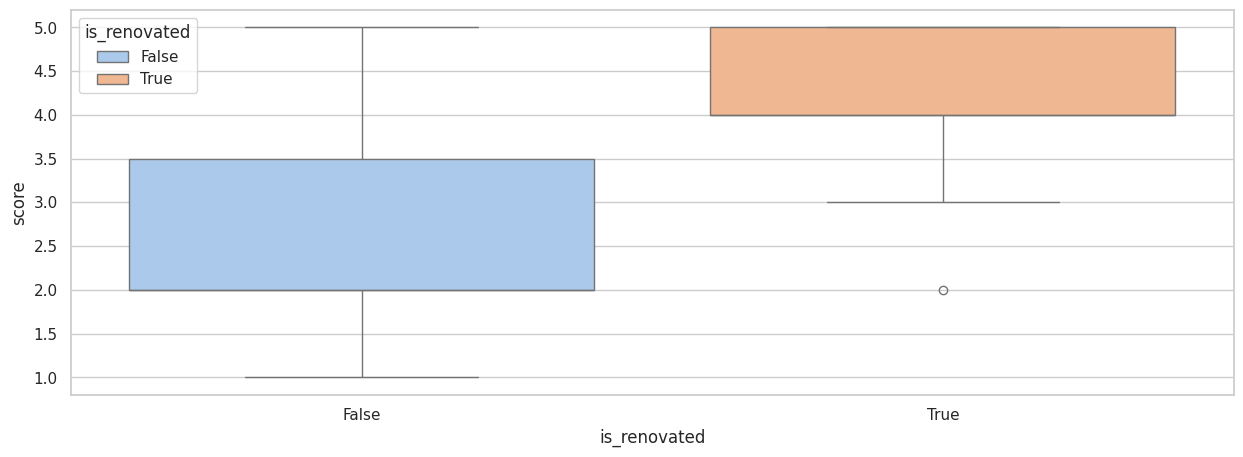

In [76]:
sns.boxplot(y = df_sold['score'],
            x = df_sold['is_renovated'],
            hue = df_sold['is_renovated']
           )
plt.show()

* บ้านที่รีโนเวท (is_renovated=True) กระจุกตัวอยู่ที่คะแนนสูง (4-5)

* มีบ้านที่รีโนเวทเพียงหลังเดียวที่ได้คะแนนต่ำกว่าปกติ จึงเป็น outlier

เช็ค outlier

In [ ]:
df_sold[ ( (df_sold['is_renovated'] == True) & (df_sold['score'] == 2) ) ].drop(columns = ['name'])

หลังตรวจสอบกับเจ้าของธุรกิจ พบว่าข้อมูลนี้กรอกผิด และต้องแก้ไขให้ถูกต้อง

In [78]:
df_sold.loc[(df_sold['is_renovated'] == True) & (df_sold['score'] == 2), 'is_renovated'] = False

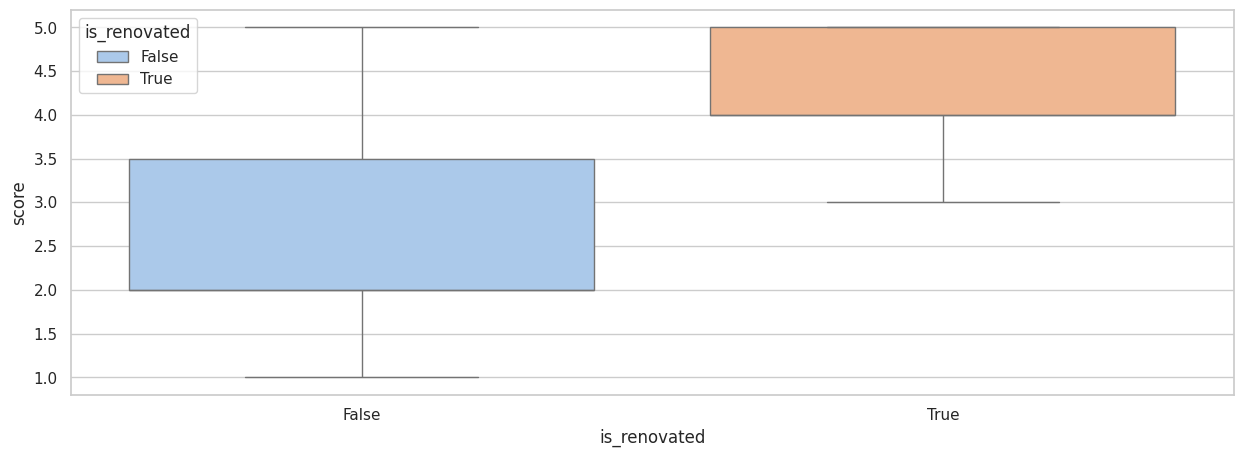

In [79]:
sns.boxplot(y = df_sold['score'],
            x = df_sold['is_renovated'],
            hue = df_sold['is_renovated']
           )
plt.show()

In [80]:
df_sold.is_renovated.value_counts()

,count
is_renovated,
True,25
False,12


In [81]:
pd.crosstab(df_sold['score'], df_sold['is_renovated'])

is_renovated,False,True
score,,
1.000,2,0
2.000,5,0
2.500,1,0
3.000,0,1
3.500,2,3
4.000,0,9
4.500,0,2
5.000,2,10


มีเพียง 2 ระดับคะแนน (3.5 และ 5.0) ที่มีทั้งบ้านรีโนเวทและไม่รีโนเวท ดังนั้นจึงเปรียบเทียบราคาของสองกลุ่มที่คะแนนสภาพบ้านเท่ากันได้เฉพาะสองระดับนี้

#### df_sold['transfer_fee']

In [82]:
df_sold.transfer_fee.value_counts()

,count
transfer_fee,
free,28
half,5
unspecified,4


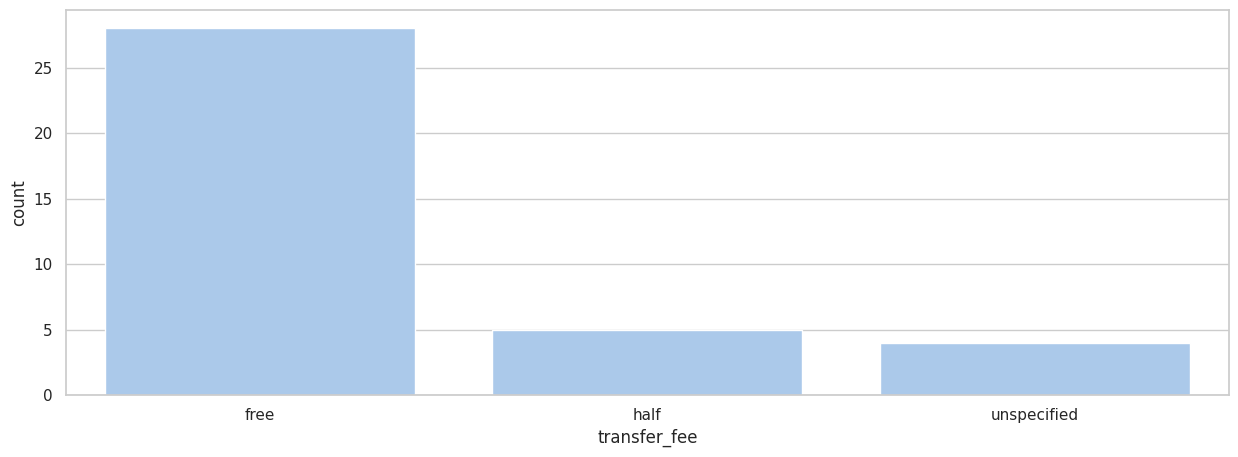

In [83]:
sns.countplot(data = df_sold, x = "transfer_fee")
plt.show()

#### df_sold['bedroom']

In [84]:
df_sold.bedroom.value_counts()

,count
bedroom,
2.000,23
3.000,14


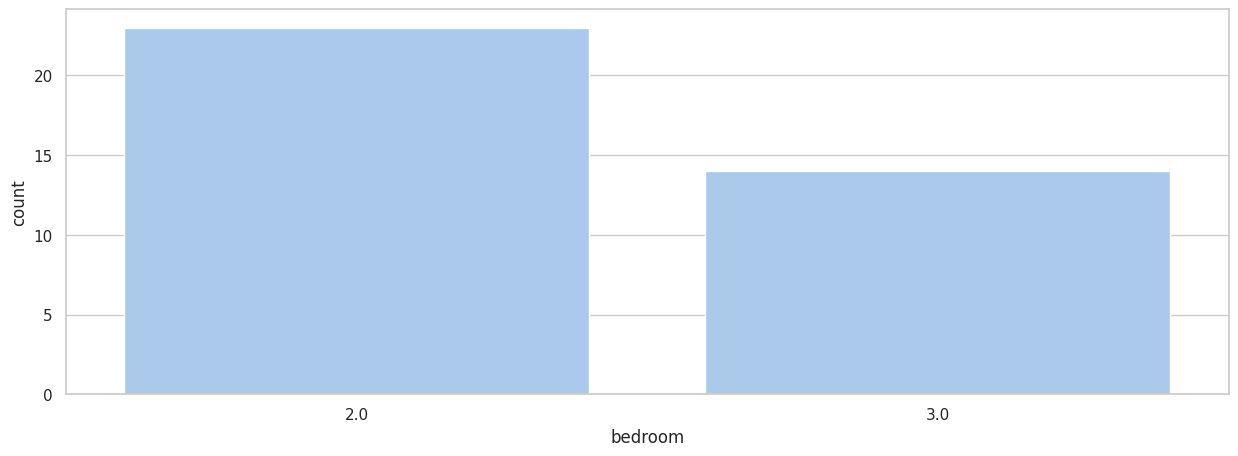

In [85]:
sns.countplot(data = df_sold, x = "bedroom")
plt.show()

In [86]:
pd.crosstab(df_sold['bedroom'], df_sold['house_type'])

house_type,singlehouse,townhouse,twinhouse
bedroom,,,
2.000,5,18,0
3.000,8,5,1


In [87]:
pd.crosstab(df_sold['bedroom'],
            df_sold['house_type'],
            values = df_sold['soldprice'],
            aggfunc = 'mean'
           )

house_type,singlehouse,townhouse,twinhouse
bedroom,,,
2.000,"1,510,000.000","1,018,333.333",NaN
3.000,"2,266,250.000","1,566,000.000","2,650,000.000"


#### df_sold['bathroom']

In [88]:
df_sold.bathroom.value_counts()

,count
bathroom,
1.000,19
2.000,16
3.000,2


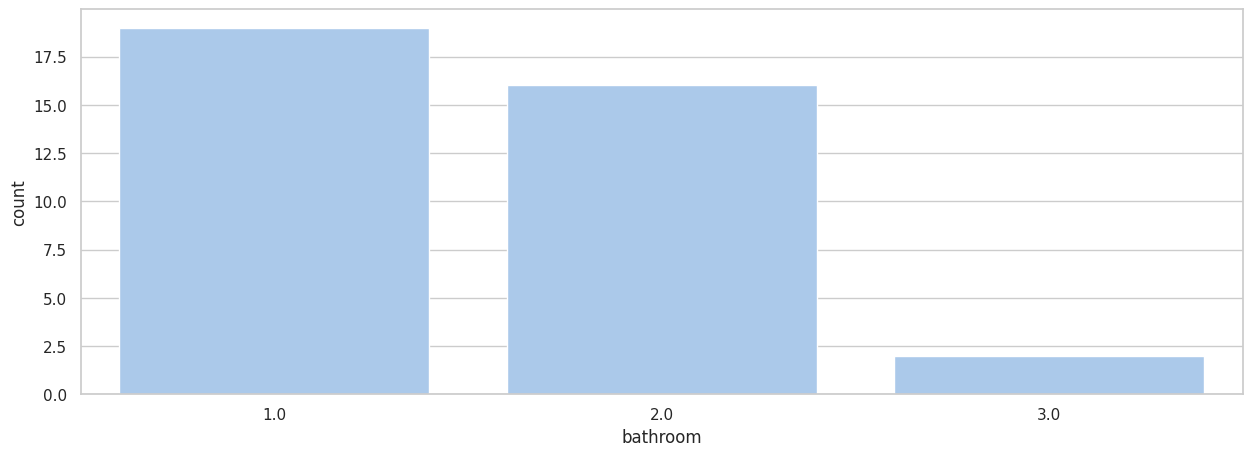

In [89]:
sns.countplot(data = df_sold, x = "bathroom")
plt.show()

#### df_sold['parking']

In [90]:
df_sold.parking.value_counts()

,count
parking,
1.000,22
2.000,12
3.000,2
4.000,1


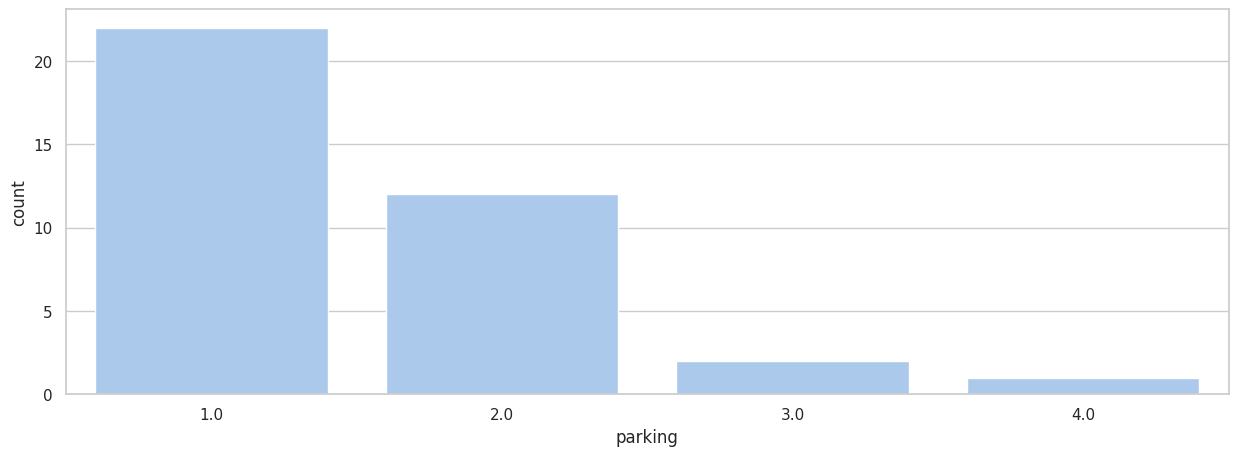

In [91]:
sns.countplot(data = df_sold, x = "parking")
plt.show()

#### df_sold['score']

In [92]:
df_sold.score.value_counts().sort_index()

,count
score,
1.000,2
2.000,5
2.500,1
3.000,1
3.500,5
4.000,9
4.500,2
5.000,12


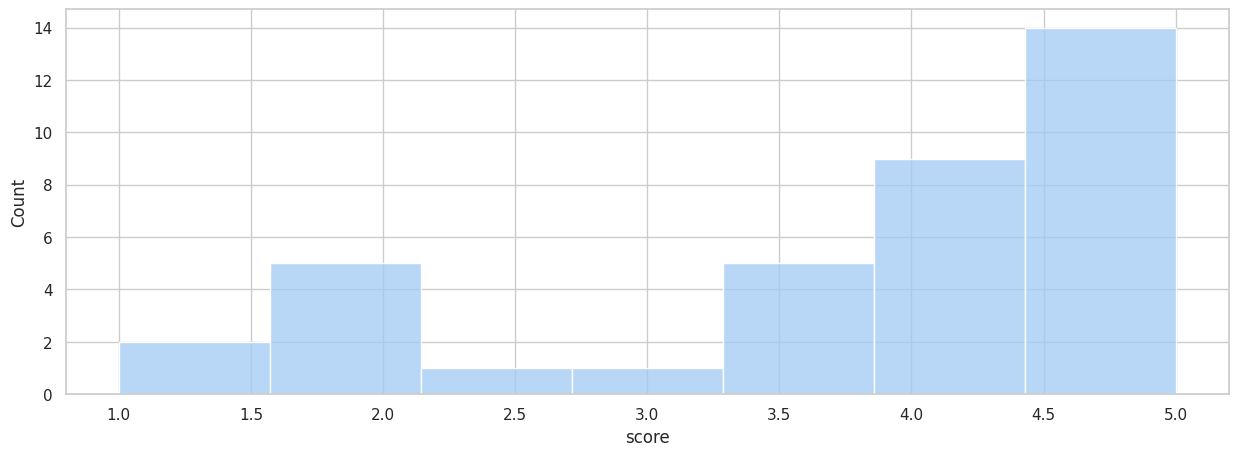

In [93]:
sns.histplot(x = df_sold['score'])
plt.show()

In [94]:
df_sold.groupby('score', observed = False)['soldprice'].agg(['mean', 'count'])

,mean,count
score,,
1.000,"645,000.000",2
2.000,"1,060,000.000",5
2.500,"860,000.000",1
3.000,"1,890,000.000",1
3.500,"1,488,000.000",5
4.000,"1,438,888.889",9
4.500,"2,300,000.000",2
5.000,"1,680,000.000",12


จากตารางจะเห็นว่า โดยภาพรวมแล้ว ราคาขายเฉลี่ยในแต่ละระดับคะแนนไม่ได้เพิ่มขึ้นตามระดับคะแนนที่สูงขึ้น อย่างไรก็ตาม บางระดับคะแนนมีบ้านเพียง 1 หลังเท่านั้น

#### df_sold['area']

In [95]:
df_sold['area'].value_counts()

,count
area,
muang_pakphriao,9
saohai,9
muang_others,9
kaengkhoi,6
others_district,4


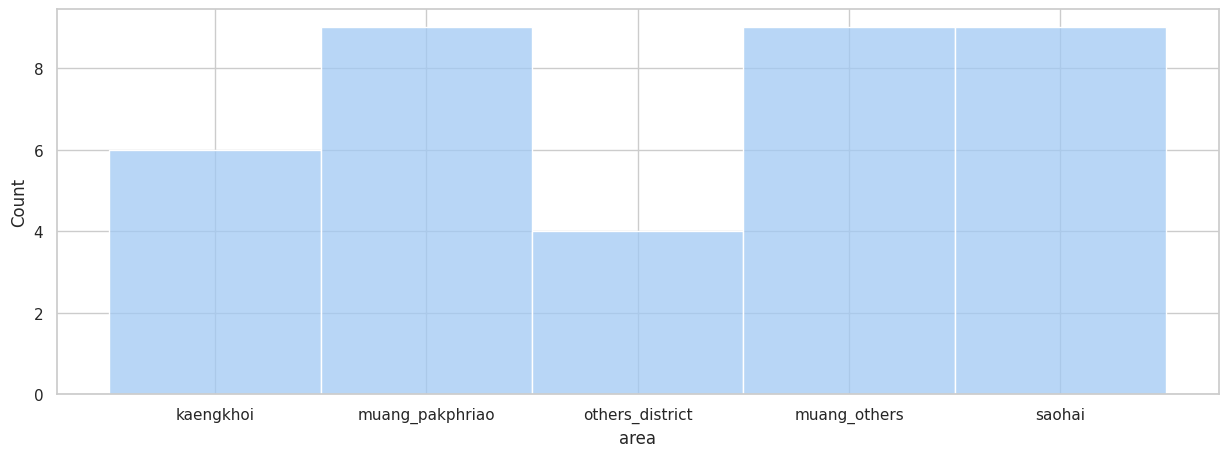

In [96]:
sns.histplot(x = df_sold['area'])
plt.show()

#### Grouped

In [97]:
df_sold[['area', 'is_renovated']].value_counts().sort_index()

area             is_renovated
kaengkhoi        False           1
                 True            5
muang_others     False           3
                 True            6
muang_pakphriao  False           3
                 True            6
others_district  False           1
                 True            3
saohai           False           4
                 True            5
Name: count, dtype: int64

ในทุกพื้นที่ มีบ้านที่รีโนเวทมากกว่าบ้านที่ไม่รีโนเวท

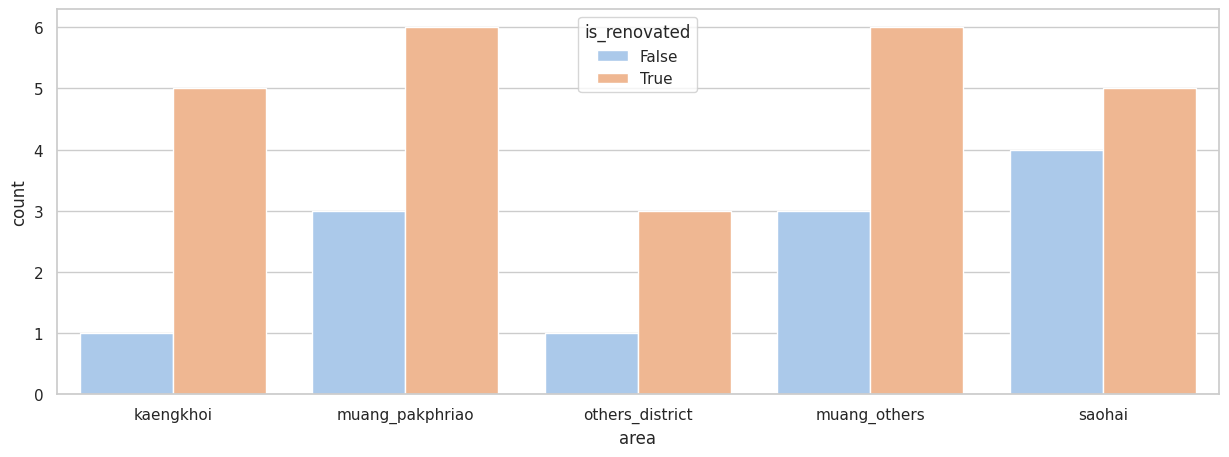

In [98]:
sns.countplot(data = df_sold,
              x = 'area',
              hue = 'is_renovated')
plt.show()

In [99]:
df_sold.groupby(['area','score'], observed = False)['soldprice'].agg(['count', 'mean'])

count          mean
area            score                     
kaengkhoi       2.000      1 1,060,000.000
                3.500      1   950,000.000
                4.000      1   900,000.000
                4.500      1 2,850,000.000
                5.000      2 2,045,000.000
muang_others    2.000      2 1,450,000.000
                3.000      1 1,890,000.000
                3.500      2 1,050,000.000
                4.000      2 1,775,000.000
                5.000      2 2,570,000.000
muang_pakphriao 2.500      1   860,000.000
                3.500      2 2,195,000.000
                4.000      4 1,675,000.000
                4.500      1 1,750,000.000
                5.000      1 1,750,000.000
others_district 4.000      1 1,150,000.000
                5.000      3 1,596,666.667
saohai          1.000      2   645,000.000
                2.000      2   670,000.000
                4.000      1   650,000.000
                5.000      4 1,097,500.000

จากตาราง พบว่าในระดับคะแนนที่เปรียบเทียบได้ 2 ระดับ (4 และ 5) บ้านในพื้นที่เสาไห้ราคาต่ำกว่าทุกพื้นที่ แต่แต่ละกลุ่มมีบ้านแค่ 1 ถึง 4 หลัง

In [100]:
df_sold.groupby('is_renovated', observed = False)['soldprice'].mean()

,soldprice
is_renovated,
False,"1,323,333.333"
True,"1,544,400.000"


In [101]:
df_sold.groupby(['is_renovated','score'], observed = False)['soldprice'].agg(['count', 'mean'])

count          mean
is_renovated score                     
False        1.000      2   645,000.000
             2.000      5 1,060,000.000
             2.500      1   860,000.000
             3.500      2 2,195,000.000
             5.000      2 2,020,000.000
True         3.000      1 1,890,000.000
             3.500      3 1,016,666.667
             4.000      9 1,438,888.889
             4.500      2 2,300,000.000
             5.000     10 1,612,000.000

In [102]:
df_sold.groupby('area', observed = False)['soldprice'].mean()

,soldprice
area,
kaengkhoi,"1,641,666.667"
muang_others,"1,731,111.111"
muang_pakphriao,"1,716,666.667"
others_district,"1,485,000.000"
saohai,"852,222.222"


In [103]:
corr_matrix = df_sold.corr(numeric_only = True)
print(corr_matrix)

              soldprice  bedroom  bathroom  parking  floor  score  \
soldprice         1.000    0.719     0.493    0.664  0.365  0.468   
bedroom           0.719    1.000     0.787    0.604  0.477  0.187   
bathroom          0.493    0.787     1.000    0.485  0.372 -0.007   
parking           0.664    0.604     0.485    1.000  0.230  0.144   
floor             0.365    0.477     0.372    0.230  1.000  0.202   
score             0.468    0.187    -0.007    0.144  0.202  1.000   
is_renovated      0.167   -0.055    -0.050    0.013  0.040  0.669   

              is_renovated  
soldprice            0.167  
bedroom             -0.055  
bathroom            -0.050  
parking              0.013  
floor                0.040  
score                0.669  
is_renovated         1.000  


In [104]:
df_sold.groupby(['house_type', 'floor'], observed = False)['soldprice'].agg(['count', 'mean'])

count          mean
house_type  floor                     
singlehouse 1.000     12 1,902,500.000
            2.000      1 2,850,000.000
townhouse   1.000     18 1,003,888.889
            2.000      5 1,618,000.000
twinhouse   2.000      1 2,650,000.000

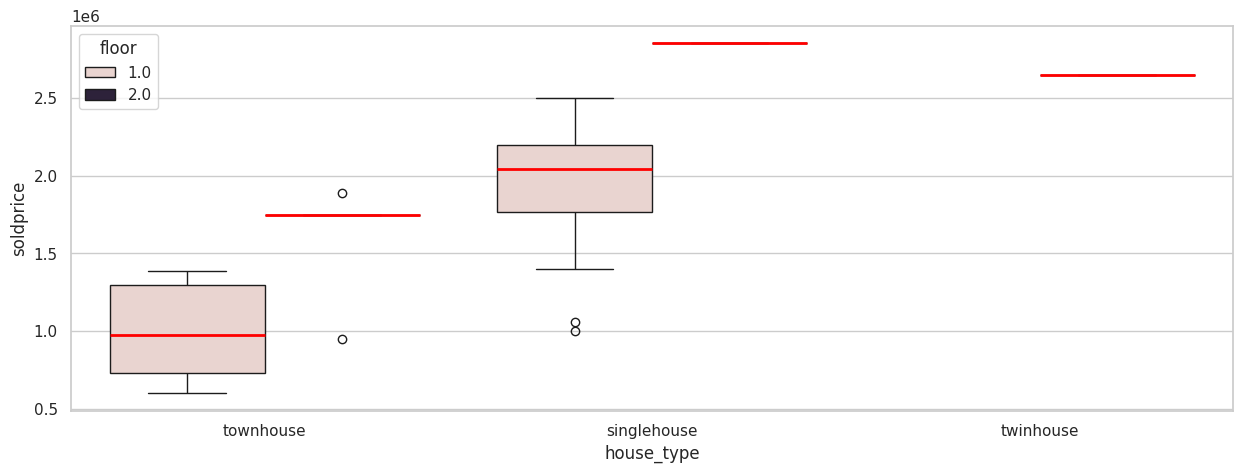

In [105]:
sns.boxplot(data = df_sold,
            x = "house_type",
            y = "soldprice",
            hue = 'floor',
            medianprops = {"color": "red", "linewidth": 2}
           )
plt.show()

จากกราฟ box plot พบว่าทั้งบ้านเดี่ยวและทาวน์เฮ้าส์ หากมี 2 ชั้นราคาจะสูงกว่า

#### Correlation

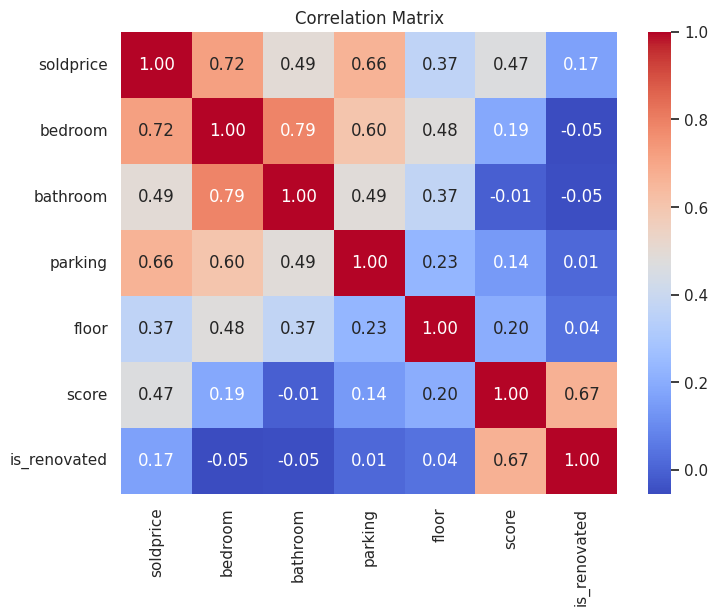

In [106]:
fig1, ax1 = plt.subplots(figsize = (8, 6))
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", fmt = ".2f", ax = ax1)
ax1.set_title("Correlation Matrix")
plt.show()

* ค่า correlation ระหว่าง **soldprice** กับ **bedroom** คือ ***0.72***

* ค่า correlation ระหว่าง **bedroom** กับ **bathroom** คือ ***0.79***

* ค่า correlation ระหว่าง **score** กับ **soldprice** คือ ***0.47***

* ค่า correlation ระหว่าง **score** กับ **is_renovated** คือ ***0.67***

#### Scatter plot

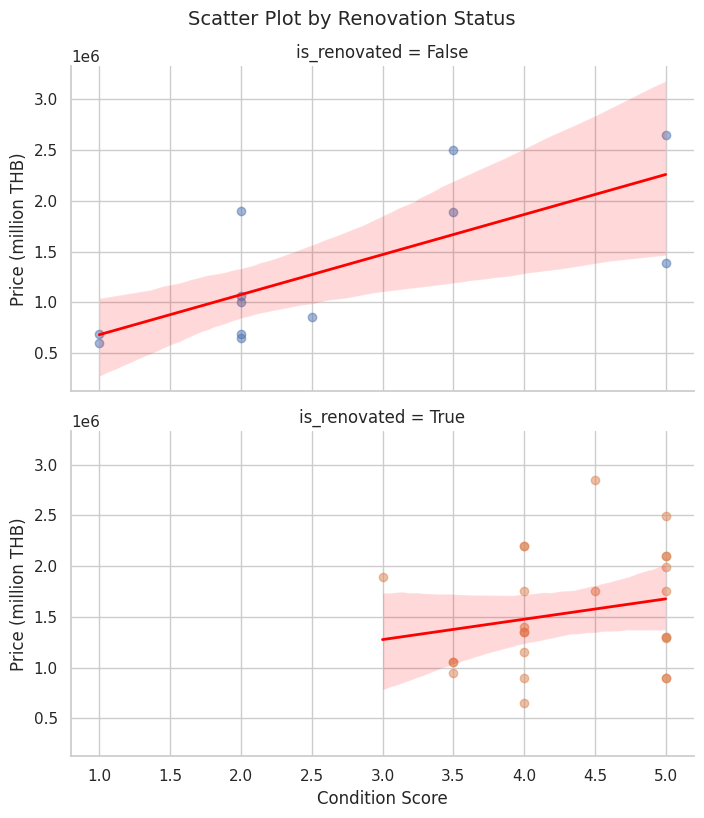

In [107]:
g = sns.lmplot(
    data = df_sold,
    x = "score",
    y = "soldprice",
    row = "is_renovated",
    hue = "is_renovated",
    palette = "deep",
    height = 4,
    aspect = 1.8,
    scatter_kws = {"alpha": 0.5},
    line_kws = {"color": "red", "linewidth": 2},
)

g.set_axis_labels("Condition Score", "Price (million THB)")
g.fig.suptitle( "Scatter Plot by Renovation Status", y = 1.02, fontsize = 14)

plt.show()

ตัวแปร score มีความสัมพันธ์เชิงบวกกับ soldprice ทั้งในกลุ่มที่รีโนเวทและไม่รีโนเวท แต่ในกลุ่มที่ไม่รีโนเวทมีความสัมพันธ์ที่ชัดเจนกว่า ส่วนในกลุ่มที่รีโนเวท บ้านส่วนใหญ่ได้คะแนน 4 ถึง 5 และบ้านที่ได้คะแนนใกล้เคียงกันมีราคาต่างกันมาก ซึ่งบ่งชี้ว่าน่าจะมีตัวแปรอื่นร่วมกำหนดราคาด้วย

In [108]:
df_sold.groupby(['area','is_renovated'], observed = False)['soldprice'].agg(['mean','count']).style.format('{:,.0f}')

ใน 3 จาก 5 พื้นที่ (แก่งคอย, อำเภออื่นๆ, เสาไห้) ราคาเฉลี่ยของบ้านที่รีโนเวทสูงกว่าบ้านที่ไม่รีโนเวท อย่างไรก็ตามข้อมูลมีจำกัดมาก

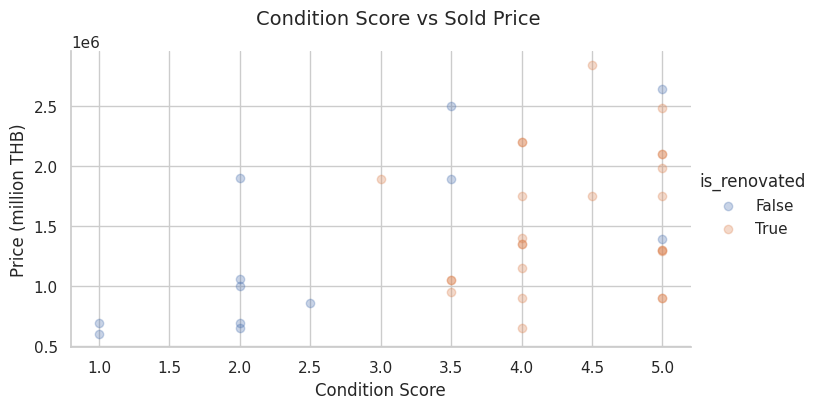

In [109]:
gr = sns.lmplot(
                data = df_sold,
                x = "score",
                y = "soldprice",
                hue = "is_renovated",
                palette = "deep",
                height = 4,
                aspect = 1.8,
                scatter_kws = {"alpha": 0.3},
                fit_reg = False
                )

gr.set_axis_labels("Condition Score", "Price (million THB)")
gr.fig.suptitle( "Condition Score vs Sold Price", y = 1.02, fontsize = 14)

plt.show()

# 5.Modeling

### 5.1 Prepare data for modeling

In [ ]:
df_sold.drop(columns = ['name']).head()

In [111]:
df_sold.shape

(37, 17)

In [112]:
df_sold.columns.to_list()

['house_id',
 'date',
 'name',
 'status',
 'soldprice',
 'transfer_fee',
 'bedroom',
 'bathroom',
 'parking',
 'floor',
 'house_type',
 'district',
 'sub_district',
 'score',
 'is_renovated',
 'close_date',
 'area']

ตัดคอลัมน์ที่ไม่สามารถใช้สร้างโมเดลได้ออก

In [113]:
df2 = df_sold.drop( columns = ['house_id','date','name','status','district','sub_district', 'close_date'] ).copy().reset_index(drop = True)

In [114]:
df2.columns.to_list()

['soldprice',
 'transfer_fee',
 'bedroom',
 'bathroom',
 'parking',
 'floor',
 'house_type',
 'score',
 'is_renovated',
 'area']

In [115]:
df2.head()

,soldprice,transfer_fee,bedroom,bathroom,parking,floor,house_type,score,is_renovated,area
0,950000,free,2.000,2.000,1.000,2.000,townhouse,3.500,True,kaengkhoi
1,1750000,free,3.000,2.000,2.000,2.000,townhouse,4.000,True,muang_pakphriao
2,1890000,half,3.000,2.000,2.000,2.000,townhouse,3.500,False,muang_pakphriao
3,1150000,free,2.000,1.000,2.000,1.000,townhouse,4.000,True,others_district
4,1000000,half,2.000,1.000,2.000,1.000,singlehouse,2.000,False,muang_others


In [116]:
df2.shape

(37, 10)

df2 = dataframe สำหรับ Modeling (ยังไม่ทำ encoding)

#### One-hot Encoding


In [117]:
df2.head()

,soldprice,transfer_fee,bedroom,bathroom,parking,floor,house_type,score,is_renovated,area
0,950000,free,2.000,2.000,1.000,2.000,townhouse,3.500,True,kaengkhoi
1,1750000,free,3.000,2.000,2.000,2.000,townhouse,4.000,True,muang_pakphriao
2,1890000,half,3.000,2.000,2.000,2.000,townhouse,3.500,False,muang_pakphriao
3,1150000,free,2.000,1.000,2.000,1.000,townhouse,4.000,True,others_district
4,1000000,half,2.000,1.000,2.000,1.000,singlehouse,2.000,False,muang_others


In [118]:
dummies = pd.get_dummies(df2['house_type'], drop_first = True)
dummies.head()

,townhouse,twinhouse
0,True,False
1,True,False
2,True,False
3,True,False
4,False,False


In [119]:
df3 = pd.concat([df2, dummies], axis = 1)
df3.head()

,soldprice,transfer_fee,bedroom,bathroom,parking,floor,house_type,score,is_renovated,area,townhouse,twinhouse
0,950000,free,2.000,2.000,1.000,2.000,townhouse,3.500,True,kaengkhoi,True,False
1,1750000,free,3.000,2.000,2.000,2.000,townhouse,4.000,True,muang_pakphriao,True,False
2,1890000,half,3.000,2.000,2.000,2.000,townhouse,3.500,False,muang_pakphriao,True,False
3,1150000,free,2.000,1.000,2.000,1.000,townhouse,4.000,True,others_district,True,False
4,1000000,half,2.000,1.000,2.000,1.000,singlehouse,2.000,False,muang_others,False,False


In [120]:
dummies2 = pd.get_dummies(df2['area'], drop_first = True)
dummies2.head()

,muang_others,muang_pakphriao,others_district,saohai
0,False,False,False,False
1,False,True,False,False
2,False,True,False,False
3,False,False,True,False
4,True,False,False,False


In [121]:
df3 = pd.concat([df3, dummies2], axis = 1)
df3.head()

,soldprice,transfer_fee,bedroom,bathroom,parking,floor,house_type,score,is_renovated,area,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,free,2.000,2.000,1.000,2.000,townhouse,3.500,True,kaengkhoi,True,False,False,False,False,False
1,1750000,free,3.000,2.000,2.000,2.000,townhouse,4.000,True,muang_pakphriao,True,False,False,True,False,False
2,1890000,half,3.000,2.000,2.000,2.000,townhouse,3.500,False,muang_pakphriao,True,False,False,True,False,False
3,1150000,free,2.000,1.000,2.000,1.000,townhouse,4.000,True,others_district,True,False,False,False,True,False
4,1000000,half,2.000,1.000,2.000,1.000,singlehouse,2.000,False,muang_others,False,False,True,False,False,False


In [122]:
df3 = df3.drop( columns = ['transfer_fee', 'house_type', 'area', 'bathroom'] )
df3.head()

,soldprice,bedroom,parking,floor,score,is_renovated,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,1.000,2.000,3.500,True,True,False,False,False,False,False
1,1750000,3.000,2.000,2.000,4.000,True,True,False,False,True,False,False
2,1890000,3.000,2.000,2.000,3.500,False,True,False,False,True,False,False
3,1150000,2.000,2.000,1.000,4.000,True,True,False,False,False,True,False
4,1000000,2.000,2.000,1.000,2.000,False,False,False,True,False,False,False


df3 = dataframe หลังทำ encoding

In [123]:
df3.head()

,soldprice,bedroom,parking,floor,score,is_renovated,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,1.000,2.000,3.500,True,True,False,False,False,False,False
1,1750000,3.000,2.000,2.000,4.000,True,True,False,False,True,False,False
2,1890000,3.000,2.000,2.000,3.500,False,True,False,False,True,False,False
3,1150000,2.000,2.000,1.000,4.000,True,True,False,False,False,True,False
4,1000000,2.000,2.000,1.000,2.000,False,False,False,True,False,False,False


#### Feature selection

* เลือกตัวแปรเข้าโมเดลโดยอิงจาก domain expert ซึ่งในที่นี้คือเจ้าของธุรกิจ

เก็บ row/feature twinhouse ไว้

In [124]:
df3.head(3)

,soldprice,bedroom,parking,floor,score,is_renovated,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,1.000,2.000,3.500,True,True,False,False,False,False,False
1,1750000,3.000,2.000,2.000,4.000,True,True,False,False,True,False,False
2,1890000,3.000,2.000,2.000,3.500,False,True,False,False,True,False,False


In [125]:
df_keep = df3.drop(['parking', 'floor', 'is_renovated'], axis = 1)

In [126]:
df_keep.head()

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,3.500,True,False,False,False,False,False
1,1750000,3.000,4.000,True,False,False,True,False,False
2,1890000,3.000,3.500,True,False,False,True,False,False
3,1150000,2.000,4.000,True,False,False,False,True,False
4,1000000,2.000,2.000,False,False,True,False,False,False


In [127]:
X_loocv = df_keep.drop('soldprice', axis = 1)
X_loocv.head()

,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,2.000,3.500,True,False,False,False,False,False
1,3.000,4.000,True,False,False,True,False,False
2,3.000,3.500,True,False,False,True,False,False
3,2.000,4.000,True,False,False,False,True,False
4,2.000,2.000,False,False,True,False,False,False


In [128]:
y_loocv = np.log( df_keep['soldprice'] )
y_loocv.head()

,soldprice
0,13.764
1,14.375
2,14.452
3,13.955
4,13.816


ใช้ log(soldprice) เพราะปัจจัยที่กำหนดราคาบ้าน เช่น สภาพบ้าน ประเภทบ้าน และทำเล น่าจะทำให้ราคาเปลี่ยนไปเป็นสัดส่วน (%) ของราคา มากกว่าจะเปลี่ยนเป็นจำนวนคงที่ (บาท)

> จากการปรึกษาเจ้าของธุรกิจ การปรับราคาของบ้านแต่ละหลังขึ้นอยู่กับหลายปัจจัยร่วมกัน และไม่ได้ปรับเท่ากันทุกหลัง จึงไม่มีเลขตายตัว แต่โดยรวมคือราคามีแนวโน้มจะเปลี่ยนตามสัดส่วนของราคาพื้นฐานของบ้าน (ก่อนที่ปัจจัยต่าง ๆ เช่น สภาพบ้าน ประเภทบ้าน ทำเล จะมาปรับขึ้นลง)

ตัด row/feature twinhouse ออก

In [129]:
df_keep.head(3)

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,3.500,True,False,False,False,False,False
1,1750000,3.000,4.000,True,False,False,True,False,False
2,1890000,3.000,3.500,True,False,False,True,False,False


In [130]:
df_cut = df_keep.copy()

In [131]:
df_cut.query('twinhouse == 1')

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
20,2650000,3.000,5.000,False,True,True,False,False,False


In [132]:
df_cut.drop(index = 20, inplace = True)

In [133]:
df_cut[17:21]

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
17,1400000,2.000,4.000,False,False,False,True,False,False
18,1750000,3.000,4.500,True,False,False,True,False,False
19,2490000,3.000,5.000,False,False,True,False,False,False
21,1890000,2.000,3.000,False,False,True,False,False,False


In [134]:
df_cut.drop('twinhouse', axis = 1, inplace = True)

In [135]:
df_cut.head(5)

,soldprice,bedroom,score,townhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,3.500,True,False,False,False,False
1,1750000,3.000,4.000,True,False,True,False,False
2,1890000,3.000,3.500,True,False,True,False,False
3,1150000,2.000,4.000,True,False,False,True,False
4,1000000,2.000,2.000,False,True,False,False,False


In [136]:
X_loocv_cut = df_cut.drop('soldprice', axis = 1)
X_loocv_cut.head()

,bedroom,score,townhouse,muang_others,muang_pakphriao,others_district,saohai
0,2.000,3.500,True,False,False,False,False
1,3.000,4.000,True,False,True,False,False
2,3.000,3.500,True,False,True,False,False
3,2.000,4.000,True,False,False,True,False
4,2.000,2.000,False,True,False,False,False


In [137]:
y_loocv_cut = np.log( df_cut['soldprice'] )
y_loocv_cut.head()

,soldprice
0,13.764
1,14.375
2,14.452
3,13.955
4,13.816


### 5.2 Predictive Model

* เทรนโมเดลเพื่อทำนายราคา

#### LOOCV + linear model

* จากการสำรวจข้อมูล พบบ้านแฝดเพียง 1 หลังในชุดข้อมูล การเก็บไว้อาจทำให้ coefficient ของ twinhouse ไม่น่าเชื่อถือ แต่การตัดออกก็เท่ากับทิ้งข้อมูลจริงโดยไม่มีเหตุผลรองรับเพียงพอ จึงเทรนโมเดลทั้งสองแบบ คือ **Loocv_keep** และ **Loocv_cut** เพื่อดูว่าผลที่ได้เป็นอย่างไร

* **คาดว่าโมเดล Loocv_keep ซึ่งเก็บบ้านแฝดไว้ น่าจะให้ผลแย่กว่า Loocv_cut** เพราะเมื่อใช้ leave-one-out cross-validation จะมีรอบหนึ่งที่แถวบ้านแฝดอยู่ใน test data ทำให้ train data ไม่มีตัวอย่างบ้านแฝดให้โมเดลเรียนรู้เลย ผลคือโมเดลอาจทำนายบ้านแฝดได้ไม่ดี

##### Loocv_keep model (keep twinhouse)

In [138]:
loo = LeaveOneOut()
model = LinearRegression()

y_pre = cross_val_predict(model, X_loocv, y_loocv, cv = loo)


r2 = r2_score(y_loocv, y_pre)
rmse = np.sqrt( mean_squared_error(y_loocv, y_pre) )

print('R-squared', r2)
print('RMSE', rmse)

R-squared 0.8224400976262483
RMSE 0.18438416094237317


ประสิทธิภาพของโมเดล **Loocv_keep:**

* R-squared = 0.82

* RMSE = 0.184 (หน่วยเป็น log ของราคา)

In [139]:
residuals_keep = y_loocv - y_pre

In [140]:
residuals_keep

,soldprice
0,0.018
1,0.034
2,0.222
3,0.066
4,-0.304
5,-0.148
6,0.148
7,-0.339
8,0.140
9,0.075


In [141]:
df_keep

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
0,950000,2.000,3.500,True,False,False,False,False,False
1,1750000,3.000,4.000,True,False,False,True,False,False
2,1890000,3.000,3.500,True,False,False,True,False,False
3,1150000,2.000,4.000,True,False,False,False,True,False
4,1000000,2.000,2.000,False,False,True,False,False,False
5,900000,2.000,5.000,True,False,False,False,False,True
6,1350000,2.000,4.000,True,False,True,False,False,False
7,650000,2.000,4.000,True,False,False,False,False,True
8,1900000,3.000,2.000,False,False,True,False,False,False
9,690000,2.000,2.000,True,False,False,False,False,True


In [142]:
df_keep.query('twinhouse == 1')

,soldprice,bedroom,score,townhouse,twinhouse,muang_others,muang_pakphriao,others_district,saohai
20,2650000,3.000,5.000,False,True,True,False,False,False


คาดไว้ว่าในรอบที่แถวที่ 20 (บ้านแฝด) เป็น test data การทำนายราคาบ้านแฝดน่าจะออกมาไม่ดีนัก

>แต่ผลที่ได้คือ residual ของแถวที่ 20 เท่ากับ **-0.01** ซึ่งเป็นสัดส่วนที่น้อยมาก โมเดลทำนายราคาบ้านแฝดได้ดีกว่าที่คาดไว้ คลาดเคลื่อนเพียงเล็กน้อยเท่านั้น

In [143]:
y_loocv[20]

np.float64(14.790070197962406)

In [144]:
np.exp(14.790070197962406)

np.float64(2650000.000000002)

In [145]:
y_pre[20]

np.float64(14.80144423892896)

In [146]:
np.exp(14.80144423892896)

np.float64(2680313.273972731)

In [147]:
np.exp(14.790070197962406) - np.exp(14.80144423892896)

np.float64(-30313.27397272922)

โมเดลทำนายสูงกว่าราคาจริง 30,313.27 บาท สำหรับราคาบ้านแล้ว ความคลาดเคลื่อนเพียงหลักหมื่นบาทถือว่าน้อยมาก ตามความเห็นของเจ้าของธุรกิจ

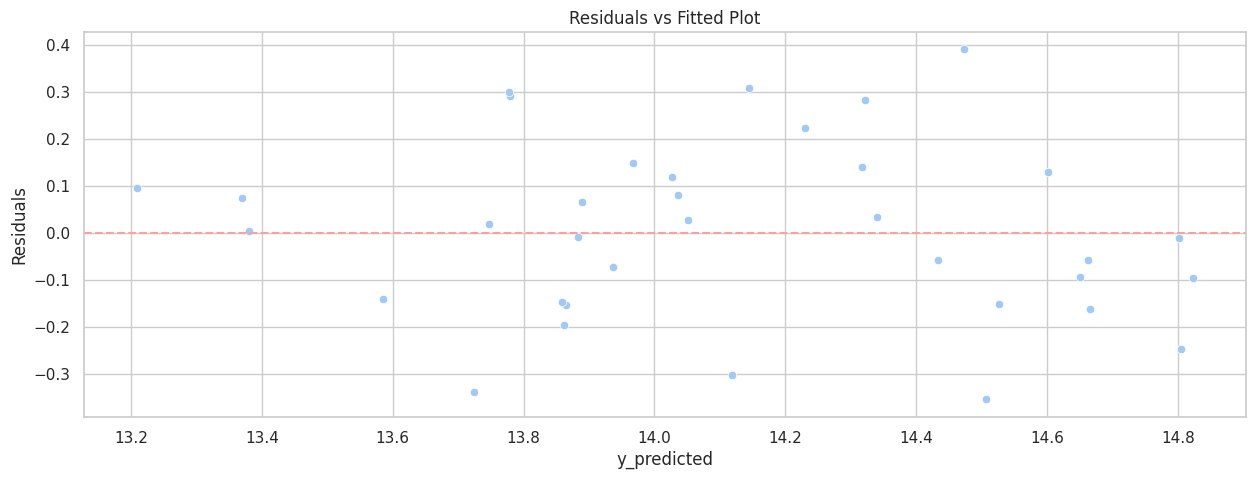

In [148]:
sns.scatterplot(x = y_pre, y = residuals_keep)

plt.axhline(y = 0, color = 'r', linestyle = '--')

plt.xlabel('y_predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Plot')
plt.show()

จาก residual plot พบว่าไม่เหลือ pattern ใน residual แล้ว

##### Loocv_cut model (drop twinhouse)

In [149]:
loo = LeaveOneOut()
model = LinearRegression()

y_pre_cut = cross_val_predict(model, X_loocv_cut, y_loocv_cut, cv = loo)


r2_cut = r2_score(y_loocv_cut, y_pre_cut)
rmse_cut = np.sqrt( mean_squared_error(y_loocv_cut, y_pre_cut) )

print('R-squared', r2_cut)
print('RMSE', rmse_cut)

R-squared 0.8096949236794208
RMSE 0.1869178984228807


ประสิทธิภาพของโมเดล **Loocv_cut**:

* R-squared = 0.81

* RMSE = 0.187 (หน่วยเป็น log ของราคา)

In [150]:
residuals_cut = y_loocv_cut - y_pre_cut

In [151]:
residuals_cut

,soldprice
0,0.018
1,0.034
2,0.222
3,0.066
4,-0.304
5,-0.148
6,0.148
7,-0.339
8,0.140
9,0.075


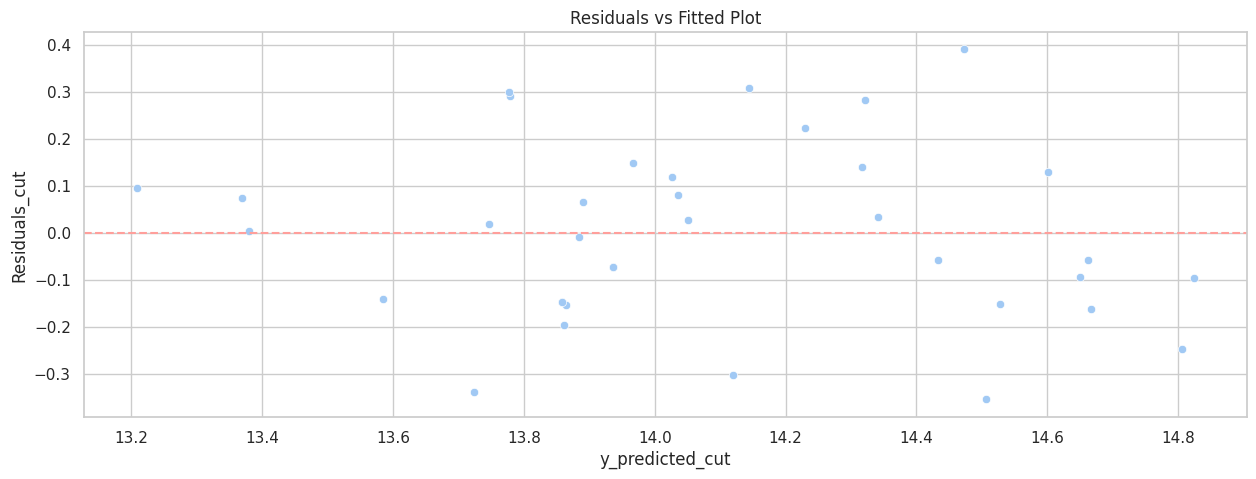

In [152]:
sns.scatterplot(x = y_pre_cut, y = residuals_cut)

plt.axhline(y = 0, color = 'r', linestyle = '--')

plt.xlabel('y_predicted_cut')
plt.ylabel('Residuals_cut')
plt.title('Residuals vs Fitted Plot')
plt.show()

จาก residual plot ของโมเดล **Loocv_cut** ก็ไม่เหลือ pattern ใน residual เช่นเดียวกัน

##### Conclusion

ผลจากทั้งสองโมเดลพบว่า โมเดลที่เก็บตัวแปรและแถวข้อมูลบ้านแฝดไว้ **(Loocv_keep)** มีค่า R-squared และ RMSE ที่ **“ดูเหมือน”** จะดีกว่า

>LOOCV (out-of-sample predictive performance)

>**โมเดล (Loocv_keep):**
>* R-squared = 0.822
>* RMSE = 0.184

> **โมเดล (Loocv_cut):**
>* R-squared = 0.810
>* RMSE = 0.187

แต่เมื่อเปรียบเทียบ residual ของบ้านอีก 36 หลังที่อยู่ในทั้งสองโมเดล **พบว่า residual จากทั้งสองโมเดล “เท่ากัน” ทุกแถว**

ดังนั้น ส่วนต่างของ R-squared และ RMSE ระหว่างสองโมเดลจึงมาจากแถวที่ 20 เพียงแถวเดียว

In [153]:
pd.concat([residuals_keep, residuals_cut], axis = 1, keys = ["residuals_keep", "residuals_cut"])

,residuals_keep,residuals_cut
0,0.018,0.018
1,0.034,0.034
2,0.222,0.222
3,0.066,0.066
4,-0.304,-0.304
5,-0.148,-0.148
6,0.148,0.148
7,-0.339,-0.339
8,0.140,0.140
9,0.075,0.075


**แต่อย่างไรก็ตาม**

* การที่ **โมเดล Loocv_keep** ทำนายราคาบ้านแฝดได้ดี ทั้งที่ในรอบนั้น train data ไม่มีข้อมูลบ้านแฝดเลย ยังเป็นประเด็นที่ต้องระมัดระวัง ***เพราะโมเดลไม่ได้เรียนรู้รูปแบบของบ้านแฝดจริง ๆ***

**จากการตรวจสอบพบว่า**

* ในรอบที่แถวที่ 20 (บ้านแฝด) เป็น test data ใน train data ไม่มีบ้านแฝดอยู่เลย โมเดลจึงเรียนรู้ coefficient ของ twinhouse ไม่ได้ และทำนายราคาบ้านหลังนี้ด้วยสูตรเดียวกับ singlehouse ซึ่งเป็น ***reference category*** ดังนั้น ค่าทำนายที่ใกล้เคียงราคาจริงของบ้านแฝดหลังนี้ จึงเป็นผลจากราคาของบ้านหลังนี้ไปใกล้เคียงกับบ้านเดี่ยวที่มีลักษณะคล้ายกับบ้านแฝดหลังนี้

* ซึ่งหลังจากสอบถามเจ้าของธุรกิจ เจ้าของธุรกิจให้คำตอบสอดคล้องกันว่า บ้าน twinhouse หลังนี้ดูภายนอกไม่ต่างจากบ้านเดี่ยวเลย และด้วยสภาพบ้านที่ค่อนข้างสวยมาก ทำให้สามารถดันราคาไปสุดเพดานของบ้านประเภทบ้านแฝดได้ จึงทำให้ราคาขายไปใกล้เคียงราคาบ้านเดี่ยวค่อนข้างมาก

* ดังนั้น จึงเป็นเพียง ***“ความบังเอิญ”*** **ที่โมเดล Loocv_keep ทำนายบ้านแฝดได้ดี** สำหรับบ้านแฝดหลังอื่น ผลการทำนายอาจไม่ดีเท่านี้

>ดังนั้น ค่า R-squared และ RMSE ที่ดูดีกว่านั้นไม่สามารถเชื่อถือได้

**จากข้อมูลทั้งหมดข้างต้น จึงตัดสินใจเลือกโมเดล Loocv_cut เป็นโมเดลต้นแบบที่จะพัฒนาต่อไปในอนาคต**

### 5.3 Evaluation of the Selected Model (Loocv_cut)

> **หมายเหตุ:** ตัวเลขจากโมเดล Loocv_cut ได้จากการเทรนโมเดลบนข้อมูลเพียง 36 แถว

แปลงราคาที่โมเดลทำนาย (y_pre_cut) จากสเกล log เป็นสเกลราคาเดิม (บาท) เพื่อคำนวณความคลาดเคลื่อนของบ้านแต่ละหลังเป็นเปอร์เซ็นต์ (%)

In [154]:
pred_price = np.exp(y_pre_cut)
pred_price

array([ 933201.22162792, 1691162.60876877, 1513616.8391179 ,
       1077020.28958669, 1355047.69117126, 1044035.46032687,
       1164207.84843147,  912426.11798935, 1651150.66475333,
        640376.59300717, 1050707.12534744, 1246612.33039281,
       2037979.26452663, 1047122.19242674, 1128714.19654328,
        964655.7491912 , 1128714.19654328, 1996919.25477243,
       1853883.62029897, 2741359.64179299, 1388719.10973137,
       1070766.60726862, 2691898.8186768 , 2332103.26343586,
       1044035.46032687, 2194747.33768173, 2341826.43166179,
       1929004.811124  , 1234932.88512275, 1265317.6972024 ,
        794400.84139585,  544897.98794507, 2305558.85467424,
       1659166.34836529,  647229.90127705,  963020.87915803])

In [155]:
actual_price = np.exp(y_loocv_cut)
actual_price = actual_price.rename('actual_price')
actual_price

,actual_price
0,"950,000.000"
1,"1,750,000.000"
2,"1,890,000.000"
3,"1,150,000.000"
4,"1,000,000.000"
5,"900,000.000"
6,"1,350,000.000"
7,"650,000.000"
8,"1,900,000.000"
9,"690,000.000"


In [156]:
pct_residual = ( ( actual_price - pred_price) / actual_price ) * 100
pct_residual = pct_residual.rename('percent_residuals')
pct_residual = pct_residual.round(2)
pct_residual

,percent_residuals
0,1.770
1,3.360
2,19.910
3,6.350
4,-35.500
5,-16.000
6,13.760
7,-40.370
8,13.100
9,7.190


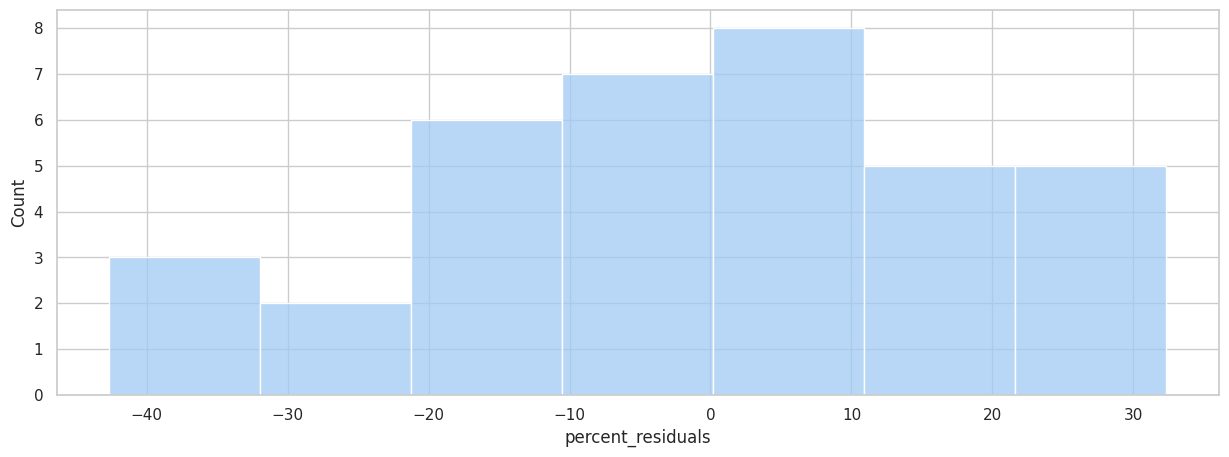

In [157]:
sns.histplot(pct_residual)
plt.show()

In [158]:
pct_residual.abs().median()

13.43

median ของความคลาดเคลื่อน (%) อยู่ที่ 13.43%

In [159]:
pct_residual.abs().sort_values().reset_index()

,index,percent_residuals
0,35,0.430
1,22,1.020
2,0,1.770
3,30,2.670
4,1,3.360
5,18,5.940
6,24,6.000
7,3,6.350
8,9,7.190
9,14,7.500


**จากทั้งหมด 36 หลัง**

>* คลาดเคลื่อนไม่เกิน 10% มี 14 หลัง คิดเป็น 39%
>* คลาดเคลื่อนไม่เกิน 20% มี 26 หลัง คิดเป็น 72%
>* คลาดเคลื่อนไม่เกิน 30% มี 32 หลัง คิดเป็น 89%
>* คลาดเคลื่อนเกิน 30%   มี  4 หลัง คิดเป็น 11%

ดังนั้นบ้านมากกว่าสองในสามถูกทำนายคลาดเคลื่อนไม่เกิน 20% อย่างไรก็ตาม มี 4 หลัง (ราว 11%) ที่ทำนายคลาดเคลื่อนเกิน 30% จึงไม่ควรตีความว่าโมเดลแม่นสม่ำเสมอกับบ้านทุกหลัง

> ตัวเลขเหล่านี้เป็นผลเพียงเบื้องต้นเท่านั้น


In [160]:
(pred_price - actual_price).abs().round(2).median()

170429.63

ค่ากลางของความคลาดเคลื่อนที่มีหน่วยเป็นบาทจะอยู่ประมาณ 170,000 บาท ซึ่งขึ้นอยู่กับราคาบ้านเป็นสำคัญ เพราะโมเดลทำนายคลาดเคลื่อนเป็นสัดส่วนของราคา

#### Actual vs. Predicted Plot (Data from the Loocv_cut Model)

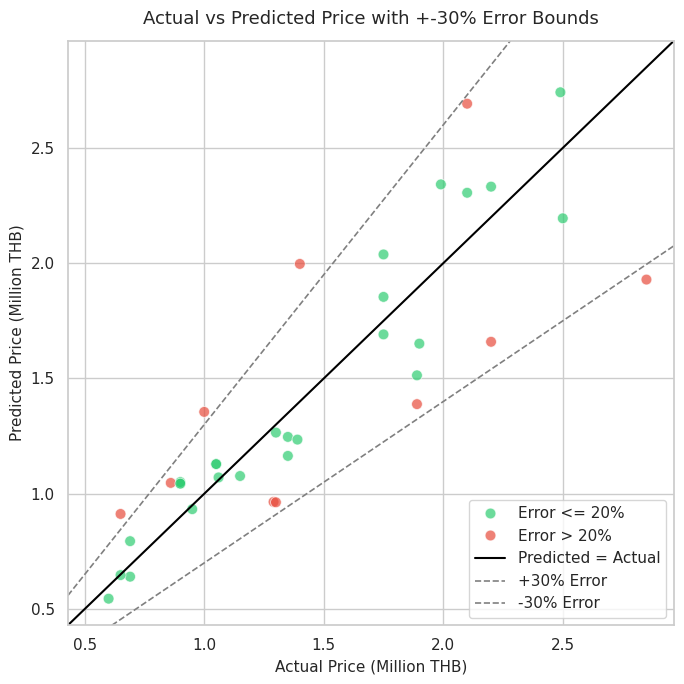

In [161]:
actual_m = actual_price / 1_000_000
pred_m = pred_price / 1_000_000

min_val = min(actual_m.min(), pred_m.min())
max_val = max(actual_m.max(), pred_m.max())

ranges = (max_val - min_val) * 0.05
limit_min = min_val - ranges
limit_max = max_val + ranges

is_within_20 = pct_residual.abs() <= 20
hue_labels = is_within_20.map({True: "Error <= 20%", False: "Error > 20%"})

fig, ax = plt.subplots(figsize = (7, 7))

sns.scatterplot(
                x = actual_m,
                y = pred_m,
                hue = hue_labels,
                palette = {"Error <= 20%": "#2ecc71",
                           "Error > 20%": "#e74c3c"},
                alpha = 0.7,
                s = 60,
                ax = ax,
               )

line_x = np.linspace(limit_min, limit_max, 100)

ax.plot(
        line_x,
        line_x,
        color = "black",
        linestyle = "-",
        linewidth = 1.5,
        label = "Predicted = Actual",
       )

ax.plot(
        line_x,
        line_x * 1.3,
        color = "grey",
        linestyle = "--",
        linewidth = 1.2,
        label = "+30% Error",
       )

ax.plot(
        line_x,
        line_x * 0.7,
        color = "grey",
        linestyle = "--",
        linewidth = 1.2,
        label = "-30% Error",
        )


ax.set_xlim(limit_min, limit_max)
ax.set_ylim(limit_min, limit_max)

ax.set_xlabel("Actual Price (Million THB)", fontsize = 11)
ax.set_ylabel("Predicted Price (Million THB)", fontsize = 11)
ax.set_title("Actual vs Predicted Price with +-30% Error Bounds", fontsize = 13, pad = 12)
ax.legend(loc = "lower right")

plt.tight_layout()
plt.show()

* จากกราฟจะเห็นว่าจุดข้อมูล 10 จุด (จุดสีแดง) จาก 36 จุดมีความคลาดเคลื่อนมากกว่า 20% และกระจายอยู่ทั้งสองฝั่งของเส้นอ้างอิง (เส้นทึบสีดำ) คือทำนายสูงกว่าค่าจริง 5 จุด และต่ำกว่าค่าจริง 5 จุด **แสดงว่าโมเดลไม่ได้มีแนวโน้มคลาดเคลื่อนไปทางใดทางหนึ่งเป็นพิเศษ**

* นอกจากนี้ ในบรรดาจุดที่คลาดเคลื่อนมากกว่า 20% มี **4 จุดที่อยู่นอกเส้นประสีเทา** ซึ่งหมายความว่า 4 จุดเหล่านั้น **คลาดเคลื่อนเกิน 30%**

#### Compare the Loocv_cut Model with the Baseline

In [162]:
X_loocv_cut.head()

,bedroom,score,townhouse,muang_others,muang_pakphriao,others_district,saohai
0,2.000,3.500,True,False,False,False,False
1,3.000,4.000,True,False,True,False,False
2,3.000,3.500,True,False,True,False,False
3,2.000,4.000,True,False,False,True,False
4,2.000,2.000,False,True,False,False,False


In [163]:
X_loocv_cut["townhouse"].value_counts()

,count
townhouse,
True,23
False,13


In [164]:
loo = LeaveOneOut()

dummy_model = DummyRegressor(strategy = "mean")

y_pred_log_base_a = cross_val_predict(dummy_model,
                                      X_loocv_cut,
                                      y_loocv_cut,
                                      cv = loo
                                     )

lr_group_model = LinearRegression()

y_pred_log_base_b = cross_val_predict(lr_group_model,
                                      X_loocv_cut[["townhouse"]],
                                      y_loocv_cut,
                                      cv = loo
                                      )



def evaluate_predictions(y_true_log, y_pred_log):

    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))

    y_true_baht = np.exp(y_true_log)
    y_pred_baht = np.exp(y_pred_log)

    abs_pct_error = np.abs((y_true_baht - y_pred_baht) / y_true_baht) * 100

    median_pct_error = np.median(abs_pct_error)

    baht_error = np.median(abs(y_true_baht - y_pred_baht))

    return rmse_log, median_pct_error, baht_error


metrics_base_a = evaluate_predictions(y_loocv_cut, y_pred_log_base_a)
metrics_base_b = evaluate_predictions(y_loocv_cut, y_pred_log_base_b)

metrics_model = evaluate_predictions(y_loocv_cut, y_pre_cut)

results_df = pd.DataFrame(
                          [metrics_base_a, metrics_base_b, metrics_model],
                          index = ["overall_mean(Baseline A)", "meanby_housetype(Baseline B)", "Loocv_cut_model"],
                          columns = ["RMSE (log price units)", "Median % Error", "Median Baht error"],
                         )


print("Baseline vs Model:")
print(results_df)

Baseline vs Model:
                              RMSE (log price units)  Median % Error  \
overall_mean(Baseline A)                       0.441          33.681   
meanby_housetype(Baseline B)                   0.350          21.314   
Loocv_cut_model                                0.187          13.430   

                              Median Baht error  
overall_mean(Baseline A)            443,126.925  
meanby_housetype(Baseline B)        308,441.702  
Loocv_cut_model                     170,429.633  


In [165]:
(0.350 - 0.187) / 0.350 * 100

46.57142857142857

Baseline A (ค่าเฉลี่ยรวม) และ Baseline B (ค่าเฉลี่ยแยกตามประเภทบ้าน) ทำนายเป็น **ค่าเฉลี่ยของ log price ที่คำนวณจากบ้านในส่วนเทรนของ LOOCV แต่ละรอบ**  โดยแบบแรกใช้บ้านทั้งหมดรวมกัน ส่วนแบบที่สองแยกตามประเภทบ้าน(ทาวน์เฮ้าส์และไม่ใช่ทาวน์เฮ้าส์)

> **ผลที่ได้คือ** โมเดล Loocv_cut ให้ผลดีกว่า baseline ทั้งสองแบบในทุกตัวชี้วัด

เมื่อเทียบ **โมเดล Loocv_cut** กับ Baseline ที่ดีที่สุดอย่าง **Baseline B (ค่าเฉลี่ยแยกตามประเภทบ้าน):** ได้ออกมาดังนี้

* **RMSE** ลดลงประมาณ 47%
* **median error** ลดลงจากประมาณ 308,000 บาท เหลือประมาณ 170,000 บาท

> แสดงว่านอกจากประเภทบ้านแล้ว ตัวแปรอื่นในโมเดลยังช่วยให้ทำนายแม่นยำขึ้นอย่างชัดเจน

### 5.4 Explanatory Analysis

* เพื่อทำความเข้าใจโมเดล

#### data for statmodel

In [166]:
df_stat = df2[df2['house_type'] != 'twinhouse']
df_stat

,soldprice,transfer_fee,bedroom,bathroom,parking,floor,house_type,score,is_renovated,area
0,950000,free,2.000,2.000,1.000,2.000,townhouse,3.500,True,kaengkhoi
1,1750000,free,3.000,2.000,2.000,2.000,townhouse,4.000,True,muang_pakphriao
2,1890000,half,3.000,2.000,2.000,2.000,townhouse,3.500,False,muang_pakphriao
3,1150000,free,2.000,1.000,2.000,1.000,townhouse,4.000,True,others_district
4,1000000,half,2.000,1.000,2.000,1.000,singlehouse,2.000,False,muang_others
5,900000,free,2.000,1.000,1.000,1.000,townhouse,5.000,True,saohai
6,1350000,free,2.000,2.000,1.000,1.000,townhouse,4.000,True,muang_others
7,650000,free,2.000,1.000,1.000,1.000,townhouse,4.000,True,saohai
8,1900000,half,3.000,2.000,2.000,1.000,singlehouse,2.000,False,muang_others
9,690000,unspecified,2.000,1.000,1.000,1.000,townhouse,2.000,False,saohai


#### modelA

ใช้ตัวแปรชุดเดียวกับโมเดล Loocv_cut และ fit กับบ้าน 36 หลังชุดเดียวกัน (ไม่รวมบ้านแฝด)

In [167]:
modelA = smf.ols('np.log(soldprice) ~ bedroom + score + C(area) + C(house_type)', data = df_stat).fit()

print(modelA.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(soldprice)   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                     30.42
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.81e-11
Time:                        17:57:00   Log-Likelihood:                 18.174
No. Observations:                  36   AIC:                            -20.35
Df Residuals:                      28   BIC:                            -7.679
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

ตัวแปรที่มีนัยสำคัญจาก modelA

*   area : muang_pakphriao = **0.021** | coef = **0.223**
*   house_type : townhouse = **0.000** | coef = **-0.355**
*   bedroom = **0.000**                | coef = **0.298**
*   score = **0.000**                  | coef = **0.150**

> ผลของ area เป็นการเทียบกับพื้นที่อ้างอิงคือแก่งคอย ส่วนผลของ townhouse เป็นการเทียบกับบ้านเดี่ยว

#### modelB

* เป้าหมายคือดูว่าตัวแปร is_renovated มีผลต่อ soldpriceหรือไม่
* เพิ่มตัวแปร is_renovated เข้าไปใน modelB

In [168]:
modelB = smf.ols('np.log(soldprice) ~ bedroom + score + is_renovated + C(area) + C(house_type)', data = df_stat).fit()

print(modelB.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(soldprice)   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                     25.92
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           9.41e-11
Time:                        17:57:00   Log-Likelihood:                 18.326
No. Observations:                  36   AIC:                            -18.65
Df Residuals:                      27   BIC:                            -4.400
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

**จาก summary ของ modelB**

จะเห็นว่าตัวแปร is_renovated มี P-value = 0.636 ซึ่งไม่มีนัยสำคัญต่อ soldprice

>ดังนั้น **ไม่พบหลักฐานว่าการรีโนเวทเพิ่มราคาได้ด้วยตัวเอง เมื่อควบคุมสภาพบ้านแล้ว**

ซึ่งสอดคล้องกับความเห็นของเจ้าของธุรกิจที่ว่า

> **"การรีโนเวทไม่ได้ทำให้ขายบ้านได้ราคาสูงขึ้นเสมอไป"** เพราะการรีโนเวทบ้านขายมีหลายระดับ ขึ้นอยู่กับสไตล์การรีโนเวทของนายทุนแต่ละคน

ตัวแปรที่มีนัยสำคัญจาก modelB

*   area : muang_pakphriao = **0.029** (เทียบกับแก่งคอย)
*   house_type : townhouse = **0.000**
*   bedroom = **0.000**
*   score = **0.000**

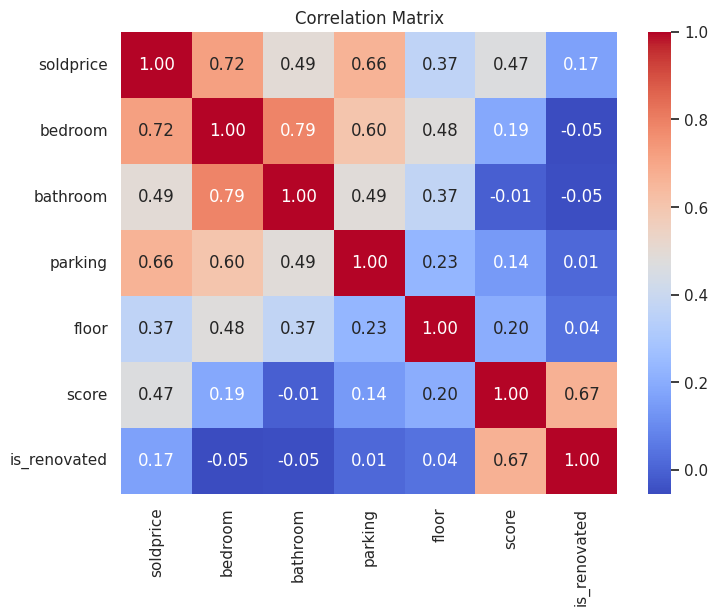

In [169]:
display(fig1)

เนื่องจาก is_renovated ไม่มีนัยสำคัญใน modelB จึงตรวจดู correlation matrix ในภาพด้านบน และพบว่า

> ค่า correlation ระหว่าง **is_renovated** กับ **score** ค่อนข้างสูงที่ ***0.67***

ดังนั้น ใน **modelC** จึงตัดตัวแปร score ออก เพื่อดูว่าตัวแปร is_renovated จะสามารถอธิบายราคาบ้านได้หรือไม่

#### modelC

In [170]:
modelC = smf.ols('np.log(soldprice) ~ bedroom + is_renovated + C(area) + C(house_type)', data = df_stat).fit()

print(modelC.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(soldprice)   R-squared:                       0.817
Model:                            OLS   Adj. R-squared:                  0.771
Method:                 Least Squares   F-statistic:                     17.82
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           8.94e-09
Time:                        17:57:01   Log-Likelihood:                 9.9689
No. Observations:                  36   AIC:                            -3.938
Df Residuals:                      28   BIC:                             8.730
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

ตัวแปรที่มีนัยสำคัญจาก modelC

*   is_renovated[T.True] = **0.001**
*   area : muang_pakphriao = **0.038** (เทียบกับแก่งคอย)
*   house_type : townhouse = **0.000**
*   bedroom = **0.000**

**จาก modelC เมื่อตัด score ออกและใช้ is_renovated เพียงตัวเดียว**

ผลคือ **ตัวแปร is_renovated กลับมีนัยสำคัญทางสถิติ** และการตัดตัวแปร score ออกทำให้ R-squared ของโมเดลลดลงจาก 0.885 เหลือ 0.817

> แสดงว่าทั้ง is_renovated และ score อธิบายราคา (ตัวแปร y) ในส่วนที่ทับซ้อนกัน

อย่างไรก็ตาม ตัวแปรที่น่าสนใจคือ **ตัวแปร score หรือคะแนนสภาพบ้าน** ซึ่งมี P-value เท่ากับ 0.000 ใน modelB แม้จะมีตัวแปร is_renovated อยู่ร่วมด้วย

* จึงสรุปได้ว่าสภาพบ้านยังมีความสัมพันธ์กับราคาอย่างมีนัยสำคัญ แม้ควบคุมตัวแปร is_renovated แล้ว

**ในชุดข้อมูลนี้ ไม่พบหลักฐานว่าการรีโนเวทเพิ่มราคาเมื่อควบคุมสภาพบ้านแล้ว ส่วนสิ่งที่สัมพันธ์กับราคาคือสภาพบ้านที่ดีกว่า**

# 6.Future Model Development

จากการพูดคุยกับเจ้าของธุรกิจ พบว่าบ้านมือสองที่ขายได้ในสระบุรีส่วนใหญ่เป็น **บ้านเดี่ยวและทาวน์เฮ้าส์** ส่วนบ้านแฝดมีไม่ถึง 5% ของบ้านที่ขายได้ทั้งหมด

เมื่อตรวจสอบกับชุดข้อมูลนี้ พบว่าข้อมูลสอดคล้องกับที่เจ้าของธุรกิจกล่าวไว้ จากบ้านมือสองที่ขายแล้ว 37 หลัง มีบ้านแฝดเพียง 1 หลัง คิดเป็นประมาณ 2.7% (ตัวเลขนี้นับเฉพาะบ้านมือสอง ไม่รวมบ้านสร้างใหม่)

หากรวมบ้านทั้งหมด ไม่ว่าจะขายแล้ว กำลังลงขายอยู่ (active) หรือถอนออกไปแล้ว (withdrawn) รวมทั้งหมด 102 หลัง มีบ้านมือสองที่เป็นบ้านแฝดเพียง 1 หลังเช่นกัน

In [171]:
df1.shape

(102, 18)

In [ ]:
df1[ df1['house_type'] == 'twinhouse' ].drop(columns = ['name'])

จากบ้านทั้งหมด 102 หลัง มีเพียง 1 หลังที่เป็นทั้งบ้านแฝดและบ้านมือสอง ส่วนอีก 3 หลังเป็นบ้านแฝดเช่นกันแต่เป็นบ้านสร้างใหม่ ซึ่งการตั้งราคาแตกต่างจากบ้านมือสอง

อีกทั้ง ผลการทดสอบในโปรเจกต์นี้แสดงให้เห็นว่าโมเดลไม่ได้เรียนรู้รูปแบบของข้อมูลบ้านแฝดจริง ๆ เพราะมีข้อมูลบ้านแฝดเพียงแถวเดียว

**ดังนั้น ในการพัฒนาโมเดลในอนาคต จึงตัดสินใจตัดบ้านแฝดออกจากข้อมูล (ทั้งแถวและตัวแปร) และกำหนดขอบเขตของโมเดลดังนี้**

> **ขอบเขตของโมเดล:** โมเดลนี้ใช้ทำนายราคาบ้านเดี่ยวและทาวน์เฮ้าส์มือสองในจังหวัดสระบุรีเท่านั้น ยังไม่ครอบคลุมบ้านแฝด เนื่องจากข้อมูลบ้านแฝดยังไม่เพียงพอให้โมเดลเรียนรู้ได้อย่างน่าเชื่อถือ

จะกลับมาพิจารณาเพิ่มบ้านแฝดเข้าไปในโมเดลอีกครั้ง เมื่อมีข้อมูลบ้านแฝดมือสองที่ขายได้ครบ 10 หลังขึ้นไป หรือเมื่อสัดส่วนบ้านแฝดสูงขึ้นอย่างมีนัยสำคัญ

**แนวทางการใช้งานเมื่อโมเดลพร้อม**

โปรเจกต์นี้ยังไม่ได้ให้คำแนะนำเรื่องการตั้งราคา หากพัฒนาโมเดลต่อด้วยข้อมูลที่มากขึ้น แนวทางการใช้งานที่ตั้งใจไว้คือช่วยให้คำแนะนำเรื่องราคาขายแก่เจ้าของบ้านที่เป็นลูกค้าของเราเช่นกัน

จากประสบการณ์ของเจ้าของธุรกิจ ลูกค้าบางรายไม่แน่ใจว่าควรตั้งราคาขายเท่าไร และบางรายนั้นมีปัญหาที่ตั้งราคาสูงเกินไป ซึ่งส่งผลต่อการขาย การให้คำแนะนำเรื่องราคาบ้านเป็นส่วนหนึ่งของการบริการของเรา

เมื่อกรอกจำนวนห้องนอน คะแนนสภาพบ้าน ประเภทบ้าน และพื้นที่ของบ้านหลังหนึ่ง โมเดลจะให้ราคาอ้างอิง จากราคาบ้านที่มีลักษณะใกล้เคียงกันในพื้นที่เดียวกันที่ขายได้จริง

โดยราคาอ้างอิงนี้ใช้เป็นจุดตั้งต้นในการแนะนำเจ้าของบ้านที่ยังไม่มีราคาในใจ หรือใช้เทียบกับราคาที่เจ้าของบ้านตั้งไว้แล้ว

แต่เนื่องจากโมเดลมีความคลาดเคลื่อน ดังนั้นเกณฑ์ที่ใช้ตัดสินว่าราคาที่ตั้งสูงเกินไปหรือต่ำเกินไป จึงยังไม่ได้ถูกกำหนดในโปรเจกต์นี้ เพราะกลุ่มตัวอย่างปัจจุบันยังเล็กเกินไปที่จะกำหนดได้อย่างน่าเชื่อถือ